# Caso A – Streaming musical: qué escucha el oyente peruano
Dataset base: Spotify Tracks Dataset — 114,000 canciones con audio features / Kaggle – Top Spotify Songs in 73 Countries, actualización diaria, incluye Perú / Kaggle - Enriquecimiento aplicado (Vía 2):

* MusicBrainz API: Tipo de artista (solista/banda), país de origen y tags de género del artista.


*Cliente:* (**Latam Music Group**) Distribuidora musical latinoamericana que evalúa entrar al mercado peruano.

*Decisión del cliente:* Qué artistas y géneros fichar para Perú.

*Pregunta central:* ¿Qué características musicales conectan con el oyente peruano y qué géneros tienen mayor potencial de crecimiento local?

### **Contexto de Negocio:**

El mercado de transmisión de música en streaming en Perú presenta dinámicas de consumo particulares, influenciadas por tendencias globales, ritmos tropicales y preferencias culturales locales. Para Latam Music Group, la selección de talento no puede basarse en intuiciones artísticas, requiere un diagnóstico guiado por datos que garantice un retorno de inversión optimizado.

### **Problemática:**

El desafío principal del sello discográfico es minimizar el riesgo de capital al firmar nuevos contratos, identificando con precisión qué tipo de producciones musicales y perfiles de artista garantizan tracción inmediata y permanencia en el mercado peruano.

### **Estrategia de segmentación de mercado:**

Para abordar esta problemática, adoptamos una estrategia deliberada de segmentación de mercado. El mercado de streaming masivo contiene millones de canciones que no generan impacto comercial significativo, por ello, la toma de decisiones no debe analizar la masa global a ciegas.

Criterios de Segmentación:

* Segmentación por Desempeño Comercial (Target: Top 50 Perú): Filtramos y aislamos el segmento de alto rendimiento (canciones en el ranking del país) para entender los patrones de éxito garantizado frente a la oferta global.

* Segmentación Acústica: Agrupamos las canciones según sus atributos de producción (bailabilidad, energía, positividad, acústica y rapeado) para identificar el perfil sonoro exacto que demanda la audiencia objetivo.

* Segmentación por Perfil de Talento: Evaluamos a los artistas según su tipo (solistas vs. bandas), su origen geográfico (país de origen del catálogo que domina el mercado) y su macro-género.

### **Estructura Analítica y preguntas con sus KPIs:**

Para responder a la pregunta central y orientar a nuestro cliente para que tome la mejor decisión posible, realizaremos un análisis exploratorio donde se han formulado 8 preguntas analíticas específicas, con el fin de recolectar los datos necesarios para guiar a Latam Music Group en su llegada al mercado peruano.

1. ¿Cómo se compara el perfil sonoro comercial de Perú frente a la tendencia global en términos de bailabilidad y energía?

   * KPI 1: Bailabilidad Promedio Perú vs. Global.
   * KPI 2: Energía Promedio Perú vs. Global.

2. ¿Qué tan concentrada está la cuota de mercado en los macro-géneros líderes dentro del Top 50 de Perú?

   * KPI 1: % Cuota del Macro-género Líder.
   * KPI 2: Concentración del Top 3 de Macro-géneros.

3. ¿Qué duración de canción se asocia con una mayor permanencia en el Top 50 peruano?

    * KPI 1: Tramo de duración con mayor permanencia (mediana de días en el chart).
    * KPI 2: % de canciones que superan la ventana crítica de 7 días en ese tramo vs. el resto.

4. ¿Cuál es la distribución del consumo comercial entre solistas y agrupaciones dentro del mercado peruano?

   * KPI 1: Cuota de Consumo de Solistas (%).
   * KPI 2: Cuota de Consumo de Agrupaciones/Bandas (%).

5. ¿Cuál es el nivel de volatilidad y el tiempo de vida medio de un lanzamiento dentro del Top 50 local?

   * KPI 1: Permanencia Promedio en Días por Canción.
   * KPI 2: Tasa de Rotación Rápida (canciones con ≤ 7 días en lista).

6. ¿Qué rangos de tempo (BPM) y positividad caracterizan a las canciones con mayor longevidad?

   * KPI 1: Valence Promedio en Éxitos Duraderos.
   * KPI 2: Tempo (BPM) Promedio en Éxitos Duraderos.

7. ¿Existe un sesgo o preferencia emocional predominante en las decisiones de escucha en Perú?

   * KPI 1: % de Canciones Eufóricas (Valence ≥ 0.5).
   * KPI 2: Valence Promedio General en Perú.

8. ¿Qué países de origen concentran el catálogo internacional que domina el consumo del Top 50 peruano?
   
   * KPI 1: % de Cuota del País de Origen Líder.
   * KPI 2: Concentración del Top 3 Países de Origen.




# Carga de los Datasets base:

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import time
import os
import re
import gc
import unicodedata
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10

def cargar_csv_seguro(ruta):
    try:
        return pd.read_csv(ruta, on_bad_lines='skip', engine='python')
    except Exception:
        return pd.read_csv(ruta, sep=';', on_bad_lines='skip', engine='python')

df_tracks = cargar_csv_seguro('/content/dataset.csv')
df_universal = cargar_csv_seguro('/content/universal_top_spotify_songs.csv')

# Segmento de mercado: solo el chart de Perú
df_peru = df_universal[df_universal['country'] == 'PE'].copy()
del df_universal; gc.collect()

print(f"✅ Datasets cargados: catálogo global {df_tracks.shape} | chart Perú {df_peru.shape}")

✅ Datasets cargados: catálogo global (114000, 21) | chart Perú (29056, 25)


# Funciones de limpieza y utilidades (uso global):

In [2]:

# 1) Se quitan las tildes en vez de borrar la letra: "La Única Tropical" → "la unica tropical"
# 2) Las colaboraciones ahora sí se separan. El patrón anterior r'\b(,)\b' nunca detectaba "Bad Bunny, Feid" (después de la coma hay un espacio, no una letra), por eso aparecían artistas como "bad bunny feid" o "feid atl jacob".
# 3) También se separa por ";" que es el separador del Spotify Tracks Dataset.

def quitar_tildes(text):
    text = unicodedata.normalize('NFKD', str(text))
    return ''.join(ch for ch in text if not unicodedata.combining(ch))


def clean_song_title(text):
    """
    Limpia títulos de canciones: quita tildes, paréntesis/corchetes (feat., remix, etc.),
    sufijos tipo " - Remastered", términos de versión y caracteres no alfanuméricos.
    """
    if pd.isna(text):
        return ""
    text = quitar_tildes(text).lower()
    text = re.sub(r'\[.*?\]|\(.*?\)', '', text)
    text = re.sub(r'\s-\s.*$', '', text)
    text = re.sub(r'\b(feat|ft|remix|live|version|edit|remastered|deluxe)\b.*', '', text)
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return " ".join(text.split())


def clean_artist_name(text):
    """
    Limpia el nombre y se queda solo con el ARTISTA PRINCIPAL cuando hay
    colaboraciones (coma, punto y coma, &, feat, ft, with, x).
    Se usa para consultar MusicBrainz y para los merges por clean_artist.
    """
    if pd.isna(text):
        return ""
    text = quitar_tildes(text).lower()
    text = re.split(r'\s*(?:,|;|&|\bfeat\b\.?|\bft\b\.?|\bwith\b|\bx\b)\s*', text)[0]
    text = re.sub(r'[^a-z0-9\s]', '', text)
    return " ".join(text.split())


def find_column(df, base_name, extra_suffixes=None):
    """
    Busca la columna correcta cuando un merge generó sufijos distintos
    (_x, _y, _base, _peru, _global, _musicset, _mb).
    """
    suffixes = ['', '_base', '_peru', '_global', '_x', '_y', '_musicset', '_mb']
    if extra_suffixes:
        suffixes = suffixes + list(extra_suffixes)
    for suf in suffixes:
        col = f"{base_name}{suf}"
        if col in df.columns:
            return col
    raise KeyError(
        f"No se encontró ninguna variante de la columna '{base_name}'. "
        f"Columnas disponibles: {list(df.columns)}"
    )

# Limpieza de llaves (se hace una sola vez aquí)
df_peru['clean_title'] = df_peru['name'].apply(clean_song_title)
df_peru['clean_artist'] = df_peru['artists'].apply(clean_artist_name)
df_tracks['clean_title'] = df_tracks['track_name'].apply(clean_song_title)
df_tracks['clean_artist'] = df_tracks['artists'].apply(clean_artist_name)

print("Ejemplos de artista principal tras la limpieza:")
print(df_peru[['artists', 'clean_artist']].drop_duplicates().head(8).to_string(index=False))


Ejemplos de artista principal tras la limpieza:
                         artists clean_artist
W Sound, Beéle, Ovy On The Drums      w sound
                           Beéle        beele
         Beéle, Ovy On The Drums        beele
                       Bad Bunny    bad bunny
                             Jin          jin
                     Danny Ocean  danny ocean
                 Alleh, Yorghaki        alleh
           Jombriel, DFZM, Jøtta     jombriel


# Fase 1 — Generador de Metadatos MusicBrainz API (Vía 2):

In [3]:

# 1) Se consulta solo el artista principal de cada canción (con la limpieza corregida).
# 2) Se consulta con el nombre original (con tildes) y búsqueda exacta entre comillas.
# 3) Solo se acepta el resultado si MusicBrainz da un score ≥ 90 (evita homónimos).
# 4) Se guardan también los TAGS de género del artista (sirven para la Pregunta 2).

RUTA_MUSICBRAINZ = '/content/musicbrainz_api_artists_v2.csv'
MB_HEADERS = {'User-Agent': 'UTEC-BA-CasoA/2.0 (correo-del-equipo@utec.edu.pe)'}  # ← poner un correo real del equipo

if os.path.exists(RUTA_MUSICBRAINZ):
    print("✅ Usando musicbrainz_api_artists_v2.csv ya existente — NO se vuelve a consultar la API.")
    df_musicbrainz = pd.read_csv(RUTA_MUSICBRAINZ)
    print(f"   Registros cargados: {len(df_musicbrainz)}")
else:
    artistas = pd.DataFrame({
        'nombre_consulta': df_peru['artists'].dropna().astype(str)
                           .str.split(r'\s*,\s*').str[0].str.strip()
    })
    artistas['clean_artist'] = artistas['nombre_consulta'].apply(clean_artist_name)
    artistas = artistas[artistas['clean_artist'] != ''].drop_duplicates('clean_artist')
    print(f"⏳ Consultando MusicBrainz para {len(artistas)} artistas principales (~1 consulta/seg)...")

    registros, sin_match, errores_api = [], 0, 0
    for _, fila in artistas.iterrows():
        params = {'query': f'artist:"{fila.nombre_consulta}"', 'fmt': 'json', 'limit': 5}
        try:
            r = requests.get('https://musicbrainz.org/ws/2/artist/', params=params,
                             headers=MB_HEADERS, timeout=20)
            if r.status_code != 200:
                errores_api += 1
            else:
                candidatos = r.json().get('artists', [])
                top = candidatos[0] if candidatos else None
                if top and int(top.get('score', 0)) >= 90:
                    tags = sorted(top.get('tags', []), key=lambda t: -t.get('count', 0))
                    begin = (top.get('life-span') or {}).get('begin') or ''
                    registros.append({
                        'clean_artist': fila.clean_artist,
                        'nombre_consulta': fila.nombre_consulta,
                        'mb_artist_name': top.get('name'),
                        'mb_score': int(top.get('score', 0)),
                        'artist_type': top.get('type'),
                        'artist_country': top.get('country'),
                        'career_start_year': pd.to_numeric(begin[:4], errors='coerce'),
                        'mb_tags': '; '.join(t['name'] for t in tags[:8]),
                    })
                else:
                    sin_match += 1
        except Exception:
            errores_api += 1
        time.sleep(1.1)

    columnas_mb = ['clean_artist', 'nombre_consulta', 'mb_artist_name', 'mb_score',
                   'artist_type', 'artist_country', 'career_start_year', 'mb_tags']
    df_musicbrainz = pd.DataFrame(registros, columns=columnas_mb)
    if df_musicbrainz.empty:
        raise RuntimeError("MusicBrainz no devolvió resultados (¿sin internet o API caída?). "
                           "No se guardó el caché: vuelvan a ejecutar esta celda en unos minutos.")
    df_musicbrainz.to_csv(RUTA_MUSICBRAINZ, index=False)
    print(f"✅ Guardado en {RUTA_MUSICBRAINZ}")
    print("   ⚠️ DESCARGUEN este CSV ahora (clic derecho → Descargar): Colab borra /content al cerrar la sesión.")
    print(f"   Artistas consultados: {len(artistas)} | Con match (score≥90): {len(df_musicbrainz)} "
          f"| Sin match: {sin_match} | Errores: {errores_api}")

✅ Usando musicbrainz_api_artists_v2.csv ya existente — NO se vuelve a consultar la API.
   Registros cargados: 123


# Pipeline de integración (merges), bitácora de cruce y tasas de coincidencia:

In [4]:

# 1) Se marca el tipo de cruce (exacto vs. solo título) para poder filtrar.
# 2) MusicBrainz se cruza directo con el chart (por artista), no solo con las canciones que encontraron pareja en el catálogo global.
# 3) Nuevo df_chart = chart Perú completo + MusicBrainz. El chart ya trae sus propias audio features, así que el análisis sonoro usa el 100% del Top 50 Perú.

df_tracks_unique = df_tracks.drop_duplicates(subset=['clean_title', 'clean_artist']).copy()

df_musicbrainz['clean_artist'] = df_musicbrainz['clean_artist'].apply(clean_artist_name)
df_mb_unique = df_musicbrainz.drop_duplicates(subset=['clean_artist']).copy()

llaves_catalogo = pd.MultiIndex.from_frame(df_tracks_unique[['clean_title', 'clean_artist']])
mask_exacto = pd.MultiIndex.from_frame(df_peru[['clean_title', 'clean_artist']]).isin(llaves_catalogo)

df_match_1 = df_peru[mask_exacto].merge(
    df_tracks_unique, on=['clean_title', 'clean_artist'], how='left', suffixes=('_peru', '_global'))
df_match_1['tipo_match'] = 'exacto (título + artista)'

df_peru_unmatched = df_peru[~mask_exacto].copy()
df_tracks_by_title = df_tracks_unique.drop_duplicates(subset=['clean_title']).copy()
df_match_2 = df_peru_unmatched.merge(
    df_tracks_by_title, on='clean_title', how='inner', suffixes=('_peru', '_global'))
df_match_2['clean_artist'] = df_match_2['clean_artist_peru']
df_match_2['tipo_match'] = 'solo título (respaldo)'

df_merged = pd.concat([df_match_1, df_match_2], ignore_index=True)

df_chart = df_peru.merge(df_mb_unique, on='clean_artist', how='left')
assert len(df_chart) == len(df_peru), "El cruce con MusicBrainz duplicó filas"

# ---------- BITÁCORA DE CRUCE ----------
total_canciones_unicas = df_peru['clean_title'].nunique()
canciones_exacto = df_match_1['clean_title'].nunique()
canciones_matcheadas_unicas = df_merged['clean_title'].nunique()
matching_rate = canciones_matcheadas_unicas / total_canciones_unicas * 100
duplicados = df_merged.duplicated(subset=['clean_title', 'clean_artist', 'snapshot_date']).sum()

canc_chart = df_chart.drop_duplicates(subset=['clean_title', 'clean_artist'])
tasa_mb_canciones = canc_chart['artist_type'].notna().mean() * 100
tasa_mb_dias = df_chart['artist_type'].notna().mean() * 100

print("=" * 62)
print("BITÁCORA DE CRUCE")
print("=" * 62)
print("CRUCE A — Chart Perú × Spotify Tracks Dataset (llave: clean_title + clean_artist)")
print(f"  Filas chart Perú (canción-día) antes del cruce: {len(df_peru):,}")
print(f"  Filas cruzadas exacto:        {len(df_match_1):,}")
print(f"  Filas cruzadas solo título:   {len(df_match_2):,}")
print(f"  Filas sin cruce:              {len(df_peru) - len(df_merged):,}  → se excluyen SOLO del análisis de género")
print(f"  Filas duplicadas tras cruce:  {duplicados}")
print(f"  Canciones únicas en chart:    {total_canciones_unicas}")
print(f"  Canciones con cruce exacto:   {canciones_exacto}")
print(f"  Tasa de coincidencia (exacto + respaldo): {matching_rate:.2f}%")
print()
print("CRUCE B — Chart Perú × MusicBrainz (llave: clean_artist)")
print(f"  Filas antes: {len(df_peru):,} | Filas después: {len(df_chart):,} (sin duplicados)")
print(f"  Tasa de cruce sobre canciones únicas: {tasa_mb_canciones:.1f}%")
print(f"  Tasa de cruce sobre días-canción:     {tasa_mb_dias:.1f}%")
print(f"  Nulos generados en artist_type: {df_chart['artist_type'].isna().sum():,} filas "
      f"→ se excluyen solo de P4, P8 y del modelo")
print("=" * 62)
if matching_rate < 70:
    print("⚠️ Cruce A por debajo del 70%: ver justificación (solo afecta a la variable género).")
if tasa_mb_canciones >= 70:
    print("✅ Cruce B (enriquecimiento MusicBrainz) supera el 70% exigido.")
else:
    print("⚠️ Cruce B por debajo del 70%: justificar en el informe.")


BITÁCORA DE CRUCE
CRUCE A — Chart Perú × Spotify Tracks Dataset (llave: clean_title + clean_artist)
  Filas chart Perú (canción-día) antes del cruce: 29,056
  Filas cruzadas exacto:        3,308
  Filas cruzadas solo título:   5,329
  Filas sin cruce:              20,419  → se excluyen SOLO del análisis de género
  Filas duplicadas tras cruce:  0
  Canciones únicas en chart:    376
  Canciones con cruce exacto:   36
  Tasa de coincidencia (exacto + respaldo): 30.59%

CRUCE B — Chart Perú × MusicBrainz (llave: clean_artist)
  Filas antes: 29,056 | Filas después: 29,056 (sin duplicados)
  Tasa de cruce sobre canciones únicas: 71.1%
  Tasa de cruce sobre días-canción:     70.0%
  Nulos generados en artist_type: 8,705 filas → se excluyen solo de P4, P8 y del modelo
⚠️ Cruce A por debajo del 70%: ver justificación (solo afecta a la variable género).
✅ Cruce B (enriquecimiento MusicBrainz) supera el 70% exigido.


**Justificación de las tasas de cruce:**

- **Cruce A — Chart Perú × Spotify Tracks Dataset: 30.59%** (115 de 376 canciones; solo 36 con cruce exacto). Está por debajo del 70% porque el catálogo global (114,000 canciones, mayormente anglosajón/comercial) no cubre buena parte del repertorio latino del chart peruano. Este cruce solo aporta una etiqueta de género, que además resultó poco confiable: una misma canción figura como "latin" y "latino" a la vez. Por eso el género se identifica principalmente con los tags de MusicBrainz, y la etiqueta de Spotify es solo un complemento. **Fuera de esa etiqueta de género complementaria, ninguna otra pregunta ni modelo depende de este cruce.**

- **Cruce B — Chart Perú × MusicBrainz (enriquecimiento, Vía 2): 71.1% de las canciones y 70.0% de los días-canción.** Cumple el mínimo del 70%.
- **País de origen (P8): 62.2% de cobertura.** Está por debajo del 70% porque MusicBrainz no registra el país de todos los artistas. La pregunta 8 se calcula sobre las 234 canciones con país conocido y se interpreta como la composición del catálogo identificado, no del total.

- **Audio features: 100% de cobertura.** El dataset del chart peruano ya las trae, así que las preguntas 1, 5, 6, 7 y los modelos usan el Top 50 Perú completo, sin depender de ningún cruce.

# Cobertura real de metadata MusicBrainz por pregunta:

In [5]:

df_check = df_chart.drop_duplicates(subset=['clean_title']).copy()
total_canciones = len(df_check)

cobertura_type = df_check['artist_type'].notna().mean() * 100
cobertura_country = df_check['artist_country'].notna().mean() * 100
cobertura_tags = df_check['mb_tags'].notna().mean() * 100

print(f"📊 COBERTURA DE METADATA MUSICBRAINZ (sobre las {total_canciones} canciones del chart Perú)")
print(f" • artist_type (P4 y modelo):    {cobertura_type:.1f}% ({df_check['artist_type'].notna().sum()}/{total_canciones})")
print(f" • artist_country (P8 y modelo): {cobertura_country:.1f}% ({df_check['artist_country'].notna().sum()}/{total_canciones})")
print(f" • mb_tags (P2):                 {cobertura_tags:.1f}% ({df_check['mb_tags'].notna().sum()}/{total_canciones})")

📊 COBERTURA DE METADATA MUSICBRAINZ (sobre las 376 canciones del chart Perú)
 • artist_type (P4 y modelo):    71.8% (270/376)
 • artist_country (P8 y modelo): 62.2% (234/376)
 • mb_tags (P2):                 56.1% (211/376)


# Cálculo único de columnas de audio features:

In [6]:

col_dance_full   = find_column(df_chart, 'danceability')
col_energy_full  = find_column(df_chart, 'energy')
col_valence_full = find_column(df_chart, 'valence')
col_tempo_full   = find_column(df_chart, 'tempo')

col_dance_tracks  = find_column(df_tracks, 'danceability')
col_energy_tracks = find_column(df_tracks, 'energy')

# EDA 1 - Calidad de datos (nulos, forma, tipos):

In [7]:

print("="*60)
print("EDA GENERAL — Calidad de datos antes de responder las preguntas")
print("="*60)

for nombre, df in [('df_tracks (catálogo global)', df_tracks),
                   ('df_peru (chart Top 50 Perú)', df_peru),
                   ('df_chart (chart Perú + MusicBrainz, base del análisis)', df_chart)]:
    print(f"\n--- {nombre} ---")
    print(f"Filas: {len(df):,} | Columnas: {df.shape[1]}")
    nulos = (df.isna().mean() * 100).sort_values(ascending=False)
    nulos = nulos[nulos > 0]
    if len(nulos) > 0:
        print("Columnas con nulos (% del total):")
        print(nulos.round(1).to_string())
    else:
        print("Sin valores nulos.")

EDA GENERAL — Calidad de datos antes de responder las preguntas

--- df_tracks (catálogo global) ---
Filas: 114,000 | Columnas: 23
Columnas con nulos (% del total):
artists       0.0
track_name    0.0
album_name    0.0

--- df_peru (chart Top 50 Perú) ---
Filas: 29,056 | Columnas: 27
Columnas con nulos (% del total):
name                  0.0
artists               0.0
album_name            0.0
album_release_date    0.0

--- df_chart (chart Perú + MusicBrainz, base del análisis) ---
Filas: 29,056 | Columnas: 34
Columnas con nulos (% del total):
mb_tags               49.6
career_start_year     41.5
artist_country        39.4
artist_type           30.0
nombre_consulta       29.9
mb_artist_name        29.9
mb_score              29.9
name                   0.0
album_release_date     0.0
artists                0.0
album_name             0.0


**LECTURA DE NEGOCIO — Calidad de datos:**

Las fuentes base están completas: el catálogo global (114,000 canciones) y el chart peruano (29,056 registros canción-día) prácticamente no tienen nulos. Los vacíos están solo en la capa de enriquecimiento de MusicBrainz: tipo de artista (30.0% de nulos), país (39.4%) y tags de género (49.6%). Es esperable, porque MusicBrainz no documenta a todos los artistas, sobre todo a los emergentes.

Para el cliente, esto significa que **todo lo relacionado con el sonido de las canciones se analiza sobre el 100% del Top 50 Perú**. Lo relacionado con el perfil del artista (tipo, país, género) se analiza sobre alrededor del 70% del consumo, y cada pregunta reporta su cobertura.

# EDA 2 - Distribución y outliers de audio features:

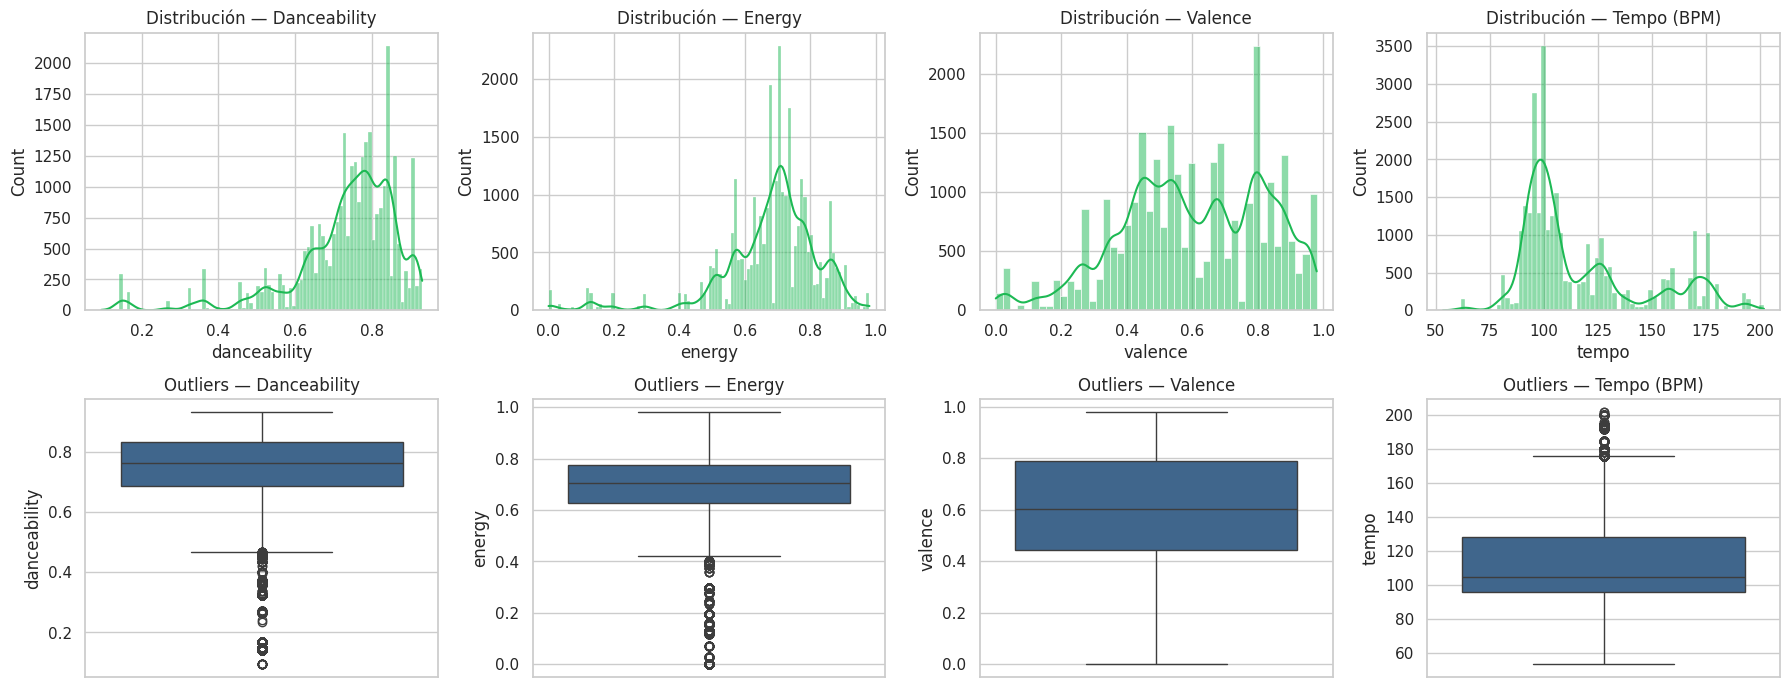

Estadísticos descriptivos — audio features del segmento Top Perú:
       danceability        energy       valence         tempo
count  29056.000000  29056.000000  29056.000000  29056.000000
mean       0.735959      0.680941      0.600672    116.641046
std        0.138501      0.149929      0.219624     28.696314
min        0.093900      0.000020      0.000010     53.376000
25%        0.685000      0.626000      0.446000     96.057000
50%        0.763000      0.705000      0.602000    104.823000
75%        0.831000      0.774000      0.788000    128.027000
max        0.932000      0.981000      0.980000    201.739000


In [8]:

features = {
    'Danceability': col_dance_full,
    'Energy': col_energy_full,
    'Valence': col_valence_full,
    'Tempo (BPM)': col_tempo_full,
}

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, (label, col) in enumerate(features.items()):
    sns.histplot(df_chart[col], kde=True, ax=axes[0, i], color='#1DB954')
    axes[0, i].set_title(f'Distribución — {label}')
    sns.boxplot(y=df_chart[col], ax=axes[1, i], color='#336699')
    axes[1, i].set_title(f'Outliers — {label}')
plt.tight_layout()
plt.show()

print("Estadísticos descriptivos — audio features del segmento Top Perú:")
print(df_chart[[col_dance_full, col_energy_full, col_valence_full, col_tempo_full]].describe())

**LECTURA DE NEGOCIO — Perfil sonoro del Top 50 Perú:**

El sonido que triunfa en Perú tiene un perfil muy definido:
- **Bailabilidad alta y homogénea:** promedio 0.74, y el 75% del consumo está por encima de 0.685. Los valores bajos son atípicos (outliers), no la norma.
- **Energía alta:** promedio 0.68, mediana 0.71.
- **Positividad (valence) repartida:** va de 0.45 a 0.79 entre los percentiles 25 y 75. Conviven canciones alegres y melancólicas, así que el ánimo no es un filtro tan estricto como la bailabilidad.
- **Tempo concentrado en el pulso del reggaetón:** la mediana es 105 BPM y el pico de la distribución está cerca de 100 BPM. El segundo pico, alrededor de 170 BPM, corresponde muy probablemente a canciones del mismo estilo medidas a "doble tiempo".

Para Latam Music Group, esto define un filtro sonoro objetivo para evaluar maquetas: bailabilidad de 0.70 o más, energía cercana a 0.70 y un pulso de 95 a 105 BPM.

# EDA 3 - Correlación entre audio features:

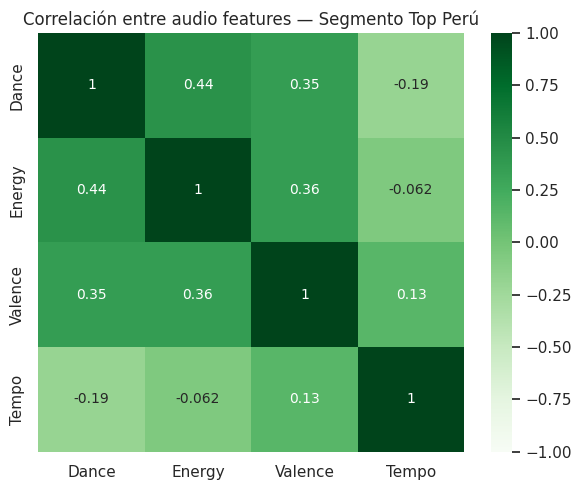

In [9]:

corr_cols = [col_dance_full, col_energy_full, col_valence_full, col_tempo_full]
corr_matrix = df_chart[corr_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap='Greens', vmin=-1, vmax=1,
            xticklabels=['Dance', 'Energy', 'Valence', 'Tempo'],
            yticklabels=['Dance', 'Energy', 'Valence', 'Tempo'])
plt.title('Correlación entre audio features — Segmento Top Perú')
plt.tight_layout()
plt.show()

**LECTURA DE NEGOCIO — Correlación entre audio features:**

Bailabilidad, energía y positividad se mueven juntas de forma moderada (correlaciones entre 0.35 y 0.44). Las canciones bailables suelen ser también enérgicas y algo más alegres: es un "paquete sonoro" que el mercado peruano consume en conjunto. El tempo, en cambio, es casi independiente de las demás (entre −0.19 y 0.13): una canción puede ser muy bailable sin ser rápida, como pasa con el reggaetón.

Para el cliente, el tempo y la bailabilidad son criterios distintos y deben evaluarse por separado. Para el modelado, ninguna correlación supera 0.5, así que las cuatro variables pueden entrar juntas en la regresión sin que se dupliquen entre sí.

# Preguntas - Visualizaciones:

A continuación, ejecutamos el EDA mediante análisis gráfico y cálculo de KPIs para responder cada pregunta estratégica del sello discográfico.


###  1.¿Cómo se compara el perfil sonoro comercial de Perú frente a la tendencia global en términos de bailabilidad y energía?

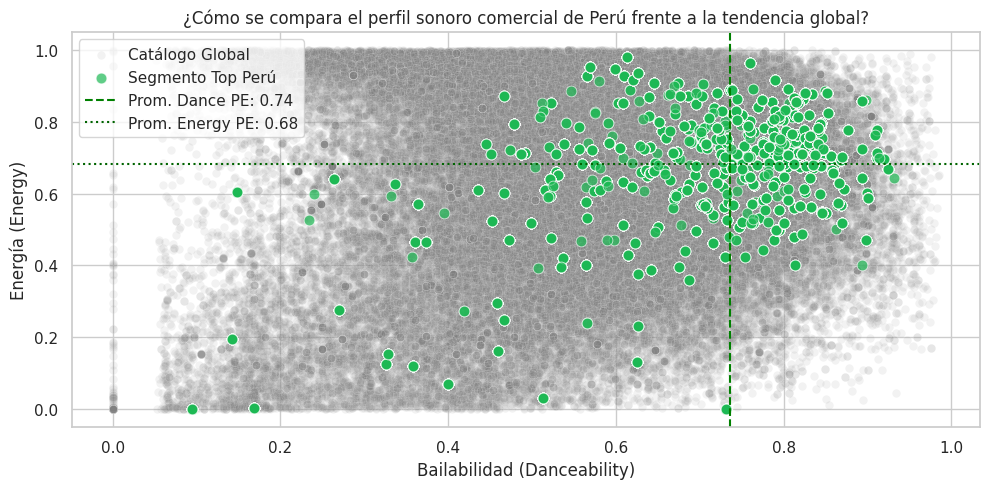

KPI 1 - Bailabilidad Promedio: Perú 0.74 vs Global 0.57
KPI 2 - Energía Promedio: Perú 0.68 vs Global 0.64


In [10]:

kpi1_dance_pe = df_chart[col_dance_full].mean()
kpi1_dance_gb = df_tracks[col_dance_tracks].mean()
kpi2_energy_pe = df_chart[col_energy_full].mean()
kpi2_energy_gb = df_tracks[col_energy_tracks].mean()

plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_tracks, x=col_dance_tracks, y=col_energy_tracks, alpha=0.1, color='gray', label='Catálogo Global')
sns.scatterplot(data=df_chart, x=col_dance_full, y=col_energy_full, alpha=0.7, color='#1DB954', s=60, label='Segmento Top Perú')

plt.axvline(kpi1_dance_pe, color='green', linestyle='--', label=f'Prom. Dance PE: {kpi1_dance_pe:.2f}')
plt.axhline(kpi2_energy_pe, color='darkgreen', linestyle=':', label=f'Prom. Energy PE: {kpi2_energy_pe:.2f}')

plt.title('¿Cómo se compara el perfil sonoro comercial de Perú frente a la tendencia global?')
plt.xlabel('Bailabilidad (Danceability)')
plt.ylabel('Energía (Energy)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"KPI 1 - Bailabilidad Promedio: Perú {kpi1_dance_pe:.2f} vs Global {kpi1_dance_gb:.2f}")
print(f"KPI 2 - Energía Promedio: Perú {kpi2_energy_pe:.2f} vs Global {kpi2_energy_gb:.2f}")

**HALLAZGO:** El catálogo que triunfa en Perú es mucho más bailable que el promedio mundial: 0.74 frente a 0.57 del catálogo global de Spotify (+0.17 puntos). También es algo más energético: 0.68 frente a 0.64 (+0.04). En el gráfico, las canciones del Top 50 Perú se agrupan en la esquina de alta bailabilidad y alta energía, mientras que el catálogo global está disperso.

La bailabilidad es el rasgo que más diferencia al mercado peruano. Para Latam Music Group, una maqueta con bailabilidad menor a 0.70 está fuera del perfil del 75% del consumo local, así que ese umbral es un filtro objetivo para evaluar nuevas firmas.

### 2.¿Qué tan concentrada está la cuota de mercado en los macro-géneros líderes dentro del Top 50 de Perú?





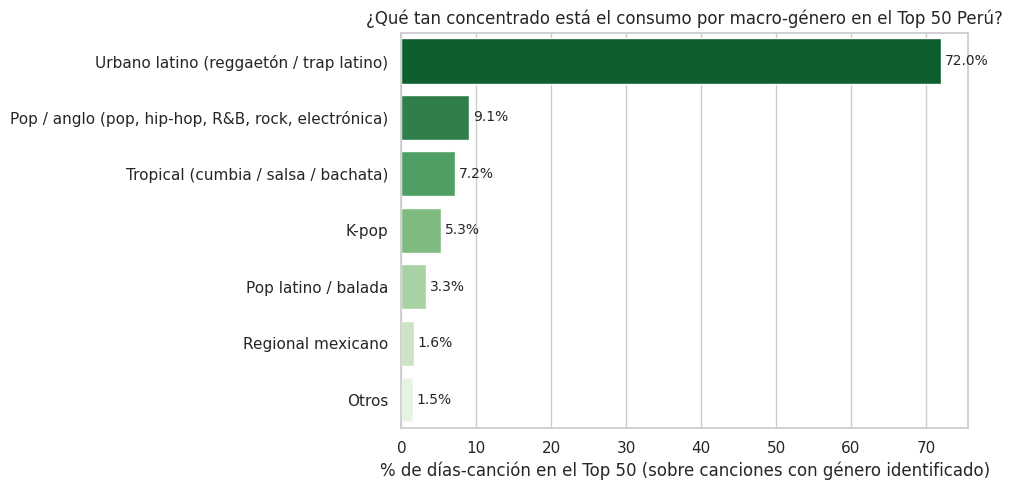


Top 5 artistas con más días-canción en el chart:
                   dias_en_chart                             macro_genero
clean_artist                                                             
feid                        2504  Urbano latino (reggaetón / trap latino)
bad bunny                   2496  Urbano latino (reggaetón / trap latino)
karol g                     2014  Urbano latino (reggaetón / trap latino)
la unica tropical            973      Tropical (cumbia / salsa / bachata)
rauw alejandro               967  Urbano latino (reggaetón / trap latino)

Cobertura de género: 57.4% de los días-canción del chart
KPI 1 - Cuota del macro-género líder (Urbano latino (reggaetón / trap latino)): 72.0%
KPI 2 - Concentración Top 3 macro-géneros: 88.3%


In [11]:

etiquetas_spotify = (df_tracks.groupby(['clean_title', 'clean_artist'])['track_genre']
                     .agg(lambda s: sorted(set(s))).rename('etiquetas_spotify').reset_index())


MAPA_GENEROS = [
    ('Urbano latino (reggaetón / trap latino)',
     ['reggaeton', 'reggaetón', 'latin trap', 'trap latino', 'urbano', 'dembow', 'latin urban', 'latin hip hop', 'perreo']),
    ('Tropical (cumbia / salsa / bachata)',
     ['cumbia', 'salsa', 'bachata', 'merengue', 'tropical', 'chicha', 'tecnocumbia']),
    ('Regional mexicano',
     ['regional mexican', 'corrido', 'mariachi', 'norteño', 'norteno', 'sierreño', 'sierreno', 'ranchera', 'banda sinaloense']),
    ('K-pop', ['k-pop', 'kpop', 'korean']),
    ('Pop latino / balada',
     ['latin pop', 'pop latino', 'balada', 'bolero', 'latin ballad', 'spanish pop']),
    ('Pop / anglo (pop, hip-hop, R&B, rock, electrónica)',
     ['pop', 'hip hop', 'hip-hop', 'rap', 'r&b', 'rnb', 'rock', 'dance', 'edm', 'house',
      'electronic', 'electro', 'indie', 'soul', 'alternative', 'trap']),
]


GENERO_MANUAL = {
    'la unica tropical': 'Tropical (cumbia / salsa / bachata)',
}

def asignar_macro_genero(etiquetas):
    etiquetas = [str(e).lower().strip() for e in etiquetas if str(e).strip()]
    if not etiquetas:
        return None
    for macro, claves in MAPA_GENEROS:
        if any(c in e for e in etiquetas for c in claves):
            return macro
    if any(e in ('latin', 'latino') for e in etiquetas):
        return 'Latino (sin subgénero identificable)'
    return 'Otros'

def a_lista(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        return [t.strip() for t in x.split(';') if t.strip()]
    return []


if 'mb_tags' not in df_chart.columns:
    df_chart['mb_tags'] = np.nan
genero_cancion = (df_chart[['clean_title', 'clean_artist', 'mb_tags']]
                  .drop_duplicates(subset=['clean_title', 'clean_artist'])
                  .merge(etiquetas_spotify, on=['clean_title', 'clean_artist'], how='left'))
genero_cancion['etiquetas'] = genero_cancion.apply(
    lambda r: a_lista(r['mb_tags']) + a_lista(r['etiquetas_spotify']), axis=1)
genero_cancion['macro_genero'] = genero_cancion['etiquetas'].apply(asignar_macro_genero)
sin_dato = genero_cancion['macro_genero'].isna()
genero_cancion.loc[sin_dato, 'macro_genero'] = genero_cancion.loc[sin_dato, 'clean_artist'].map(GENERO_MANUAL)

df_p2 = df_chart.merge(genero_cancion[['clean_title', 'clean_artist', 'macro_genero']],
                       on=['clean_title', 'clean_artist'], how='left')
cobertura_genero = df_p2['macro_genero'].notna().mean() * 100
cuota_genero = df_p2['macro_genero'].value_counts(normalize=True) * 100

kpi1_share_top = cuota_genero.iloc[0]
kpi2_share_top3 = cuota_genero.head(3).sum()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=cuota_genero.values, y=cuota_genero.index,
                 hue=cuota_genero.index, palette='Greens_r', legend=False)
plt.title('¿Qué tan concentrado está el consumo por macro-género en el Top 50 Perú?')
plt.xlabel('% de días-canción en el Top 50 (sobre canciones con género identificado)')
plt.ylabel('')
for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%', (p.get_width() + 0.5, p.get_y() + p.get_height() / 2), va='center')
plt.tight_layout()
plt.show()

top_artistas = (df_p2.groupby('clean_artist')
                .agg(dias_en_chart=('snapshot_date', 'size'), macro_genero=('macro_genero', 'first'))
                .sort_values('dias_en_chart', ascending=False).head(5))
print("\nTop 5 artistas con más días-canción en el chart:")
print(top_artistas.to_string())

print(f"\nCobertura de género: {cobertura_genero:.1f}% de los días-canción del chart")
print(f"KPI 1 - Cuota del macro-género líder ({cuota_genero.index[0]}): {kpi1_share_top:.1f}%")
print(f"KPI 2 - Concentración Top 3 macro-géneros: {kpi2_share_top3:.1f}%")


**HALLAZGO:** El urbano latino (reggaetón / trap latino) concentra el 72.0% del consumo del Top 50 Perú. Muy por detrás vienen el pop/anglo (9.1%) y el tropical (cumbia / salsa / bachata, 7.2%), y el Top 3 de macro-géneros acumula el 88.3%. Hay dos datos llamativos. Primero, el tropical es el único género con raíz local entre los tres primeros, y lo sostiene La Única Tropical, el 4.º artista con más días en el chart. Segundo, el K-pop (5.3%) tiene una presencia propia, por encima del pop latino (3.3%).

Para el cliente, la conclusión es clara: el núcleo del mercado es el urbano latino, y el tropical es el espacio natural para el talento peruano.

### 3.¿Qué duración de canción se asocia con una mayor permanencia en el Top 50 peruano?

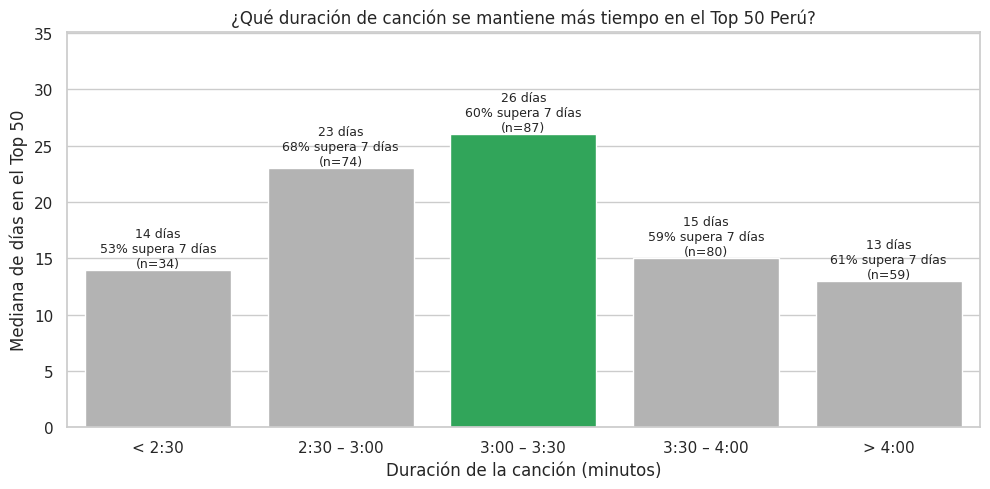


KPI 1 - Tramo de duración con mayor permanencia: 3:00 – 3:30 (mediana 26 días)
KPI 2 - % que supera la 1.ª semana: 59.8% en ese tramo vs. 61.1% en el resto

Duración mediana: Top 50 Perú 3.35 min vs. catálogo global 3.55 min
¿Las diferencias entre tramos son reales? Kruskal-Wallis p = 0.6037 → No son estadísticamente significativas
Relación duración–permanencia (Spearman): rho = -0.05, p = 0.3477


In [12]:

df_chart['snapshot_date'] = pd.to_datetime(df_chart['snapshot_date'])
df_chart['daily_rank'] = pd.to_numeric(df_chart['daily_rank'], errors='coerce')
fecha_ini, fecha_fin = df_chart['snapshot_date'].min(), df_chart['snapshot_date'].max()

df_canciones = (df_chart.sort_values('snapshot_date')
    .groupby(['clean_title', 'clean_artist'], as_index=False)
    .agg(dias_en_chart=('snapshot_date', 'nunique'),
         primera_fecha=('snapshot_date', 'min'),
         ultima_fecha=('snapshot_date', 'max'),
         rank_debut=('daily_rank', 'first'),
         artists_raw=('artists', 'first'),
         is_explicit=('is_explicit', 'first'),
         duration_ms=('duration_ms', 'first'),
         danceability=('danceability', 'mean'),
         energy=('energy', 'mean'),
         valence=('valence', 'mean'),
         tempo=('tempo', 'mean'),
         artist_type=('artist_type', 'first'),
         artist_country=('artist_country', 'first')))

df_canciones['duracion_min'] = pd.to_numeric(df_canciones['duration_ms'], errors='coerce') / 60000

df_canciones['censura_inicio'] = df_canciones['primera_fecha'].eq(fecha_ini)
df_p3 = df_canciones[~df_canciones['censura_inicio']].dropna(subset=['duracion_min']).copy()

cortes = [0, 2.5, 3.0, 3.5, 4.0, np.inf]
etiquetas = ['< 2:30', '2:30 – 3:00', '3:00 – 3:30', '3:30 – 4:00', '> 4:00']
df_p3['tramo_duracion'] = pd.cut(df_p3['duracion_min'], bins=cortes, labels=etiquetas, right=False)

res = (df_p3.groupby('tramo_duracion', observed=False)['dias_en_chart']
       .agg(canciones='size', mediana_dias='median',
            supera_7d=lambda s: (s > 7).mean() * 100)
       .reset_index())

grupos = [g['dias_en_chart'].values for _, g in df_p3.groupby('tramo_duracion', observed=True) if len(g) >= 5]
p_kruskal = stats.kruskal(*grupos).pvalue if len(grupos) >= 2 else np.nan
rho, p_spearman = stats.spearmanr(df_p3['duracion_min'], df_p3['dias_en_chart'])

res_plot = res[res['canciones'] > 0]
mejor = res_plot.loc[res_plot['mediana_dias'].idxmax()]
colores = ['#1DB954' if t == mejor['tramo_duracion'] else '#B3B3B3' for t in res_plot['tramo_duracion']]

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=res_plot, x='tramo_duracion', y='mediana_dias',
                 hue='tramo_duracion', palette=colores, legend=False)
for i, r in enumerate(res_plot.itertuples()):
    ax.annotate(f"{r.mediana_dias:.0f} días\n{r.supera_7d:.0f}% supera 7 días\n(n={r.canciones})",
                (i, r.mediana_dias), ha='center', va='bottom', fontsize=9)
ax.set_ylim(0, res_plot['mediana_dias'].max() * 1.35)
plt.title('¿Qué duración de canción se mantiene más tiempo en el Top 50 Perú?')
plt.xlabel('Duración de la canción (minutos)')
plt.ylabel('Mediana de días en el Top 50')
plt.tight_layout()
plt.show()

resto = df_p3[df_p3['tramo_duracion'] != mejor['tramo_duracion']]
kpi1_tramo = mejor['tramo_duracion']
kpi2_supera_mejor = mejor['supera_7d']
kpi2_supera_resto = (resto['dias_en_chart'] > 7).mean() * 100

print(f"\nKPI 1 - Tramo de duración con mayor permanencia: {kpi1_tramo} "
      f"(mediana {mejor['mediana_dias']:.0f} días)")
print(f"KPI 2 - % que supera la 1.ª semana: {kpi2_supera_mejor:.1f}% en ese tramo vs. {kpi2_supera_resto:.1f}% en el resto")

dur_chart = df_p3['duracion_min'].median()
dur_global = pd.to_numeric(df_tracks['duration_ms'], errors='coerce').median() / 60000

print(f"\nDuración mediana: Top 50 Perú {dur_chart:.2f} min vs. catálogo global {dur_global:.2f} min")
print(f"¿Las diferencias entre tramos son reales? Kruskal-Wallis p = {p_kruskal:.4f} → "
      f"{'Sí (p < 0.05)' if p_kruskal < 0.05 else 'No son estadísticamente significativas'}")
print(f"Relación duración–permanencia (Spearman): rho = {rho:.2f}, p = {p_spearman:.4f}")


**HALLAZGO:** Las canciones de 2:30 a 3:30 minutos muestran medianas de permanencia más altas (23 a 26 días frente a 13 a 15 en los demás tramos), pero la diferencia no es estadísticamente significativa. Además, el porcentaje que supera la primera semana es similar en todos los tramos (entre 53% y 68%). La canción mediana del Top 50 Perú dura 3.35 minutos, frente a 3.55 del catálogo global.

Para el cliente, esto también es un hallazgo útil: la duración no es lo que hace durar una canción en el chart, así que no hace falta adaptar la duración de los temas de los artistas que fiche. El modelo supervisado lo confirma, porque la duración no tiene un efecto significativo. La inversión debe enfocarse en el perfil sonoro (bailabilidad y positividad) y en el género.

### 4.¿Cuál es la distribución del consumo comercial entre solistas y agrupaciones dentro del mercado peruano?


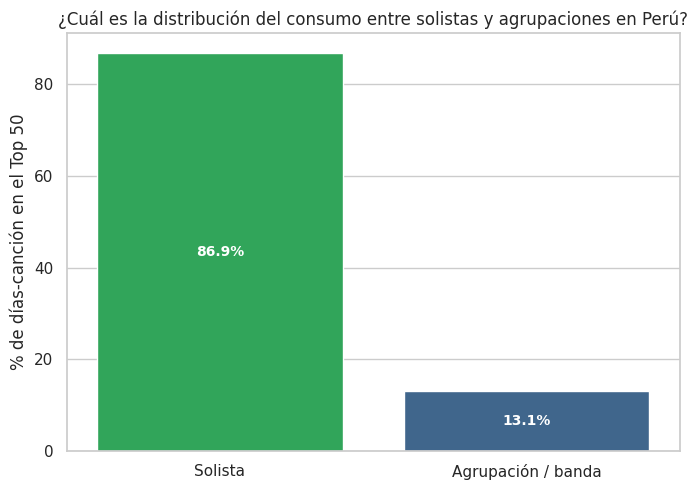

Base: 272 canciones con tipo de artista identificado
KPI 1 - Cuota de consumo de Solistas: 86.9%
KPI 2 - Cuota de consumo de Bandas/Grupos: 13.1%


In [13]:

df_p4 = df_chart[df_chart['artist_type'].isin(['Person', 'Group'])]
type_dist = df_p4['artist_type'].value_counts(normalize=True) * 100
type_dist.index = type_dist.index.map({'Person': 'Solista', 'Group': 'Agrupación / banda'})

kpi1_solo = type_dist.get('Solista', 0)
kpi2_group = type_dist.get('Agrupación / banda', 0)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=type_dist.index, y=type_dist.values,
                 hue=type_dist.index, palette=['#1DB954', '#336699'], legend=False)
plt.title('¿Cuál es la distribución del consumo entre solistas y agrupaciones en Perú?')
plt.ylabel('% de días-canción en el Top 50')
plt.xlabel('')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Base: {df_p4['clean_title'].nunique()} canciones con tipo de artista identificado")
print(f"KPI 1 - Cuota de consumo de Solistas: {kpi1_solo:.1f}%")
print(f"KPI 2 - Cuota de consumo de Bandas/Grupos: {kpi2_group:.1f}%")


**HALLAZGO:** Los solistas concentran el 86.9% del consumo del Top 50 Perú, frente a solo el 13.1% de las agrupaciones o bandas. El cálculo se hizo sobre 272 canciones con tipo de artista identificado en MusicBrainz. La audiencia peruana se conecta con marcas personales más que con colectivos.

Para Latam Music Group, los solistas son el formato que domina el volumen del mercado: compiten por casi 9 de cada 10 días de exposición en el chart. Sin embargo, el modelo supervisado muestra que no permanecen más tiempo que las agrupaciones. Ser solista es lo habitual, pero no es un requisito para durar en el chart.

### 5.¿Cuál es el nivel de volatilidad y el tiempo de vida medio de un lanzamiento dentro del Top 50 local?

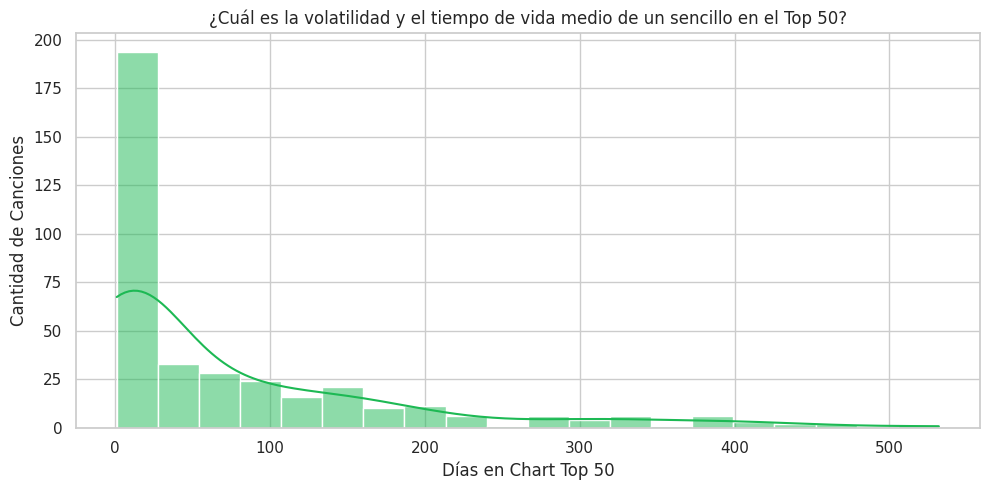

KPI 1 - Permanencia Promedio: 76.8 días
KPI 2 - Tasa de Rotación Rápida (≤ 7 días): 35.9%
Mediana de permanencia: 23 días | Máximo: 532 días


In [14]:

days_in_chart = df_chart.groupby('clean_title')['snapshot_date'].nunique()
kpi1_avg_retention = days_in_chart.mean()
kpi2_turnover_rate = (days_in_chart[days_in_chart <= 7].count() / len(days_in_chart)) * 100

plt.figure(figsize=(10, 5))
sns.histplot(days_in_chart, bins=20, kde=True, color='#1DB954')
plt.title('¿Cuál es la volatilidad y el tiempo de vida medio de un sencillo en el Top 50?')
plt.xlabel('Días en Chart Top 50')
plt.ylabel('Cantidad de Canciones')
plt.tight_layout()
plt.show()

print(f"KPI 1 - Permanencia Promedio: {kpi1_avg_retention:.1f} días")
print(f"KPI 2 - Tasa de Rotación Rápida (≤ 7 días): {kpi2_turnover_rate:.1f}%")
print(f"Mediana de permanencia: {days_in_chart.median():.0f} días | Máximo: {days_in_chart.max()} días")

**HALLAZGO:** El chart peruano tiene dos velocidades. El promedio de permanencia es de 76.8 días, pero la mediana es de solo 23 días: unos pocos éxitos muy duraderos (hasta 532 días) inflan el promedio. El 35.9% de las canciones sale del Top 50 en 7 días o menos, y el histograma muestra que la mayoría de lanzamientos dura menos de un mes, frente a un núcleo pequeño de éxitos que se quedan meses.

La primera semana es la ventana crítica: más de un tercio de los lanzamientos se descarta en ella. La inversión en promoción debe concentrarse en las primeras 1 a 3 semanas, que es cuando se decide si una canción entra al núcleo duradero o desaparece.

### 6.¿Qué rangos de tempo (BPM) y positividad caracterizan a las canciones con mayor longevidad?


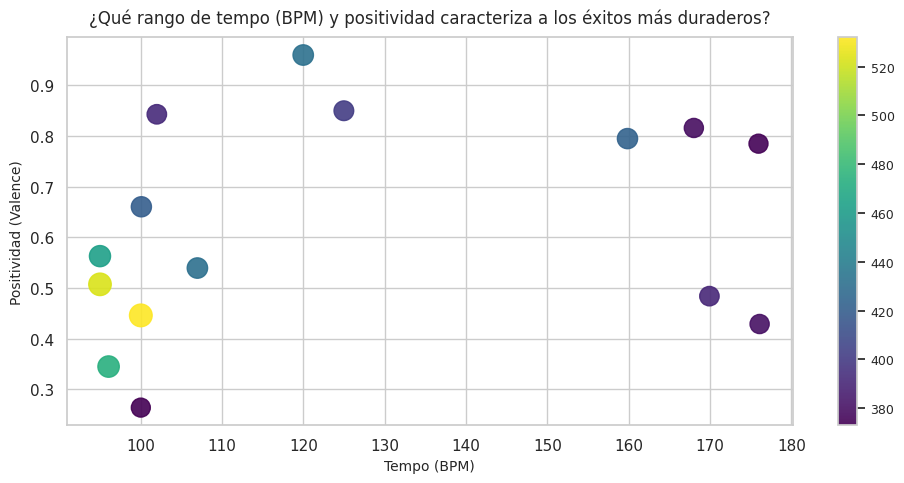

KPI 1 - Valence Promedio en Canciones Top: 0.62
KPI 2 - BPM Promedio en Canciones Top: 126.0 BPM


In [15]:

col_valence = col_valence_full
col_tempo = col_tempo_full

persistent = df_chart.groupby('clean_title').agg(
    avg_valence=(col_valence, 'mean'),
    avg_tempo=(col_tempo, 'mean'),
    permanence=('snapshot_date', 'nunique')
).sort_values(by='permanence', ascending=False).head(15)

kpi1_val_top = persistent['avg_valence'].mean()
kpi2_bpm_top = persistent['avg_tempo'].mean()

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

scatter = plt.scatter(
    data=persistent,
    x='avg_tempo',
    y='avg_valence',
    c='permanence',
    s=persistent['permanence'] * 0.5,
    cmap='viridis',
    alpha=0.9
)

plt.title('¿Qué rango de tempo (BPM) y positividad caracteriza a los éxitos más duraderos?', fontsize=12, pad=10)
plt.xlabel('Tempo (BPM)', fontsize=10)
plt.ylabel('Positividad (Valence)', fontsize=10)

cbar = plt.colorbar(scatter)
cbar.ax.tick_params(labelsize=9)

plt.tight_layout()
plt.show()

print(f"KPI 1 - Valence Promedio en Canciones Top: {kpi1_val_top:.2f}")
print(f"KPI 2 - BPM Promedio en Canciones Top: {kpi2_bpm_top:.1f} BPM")

**HALLAZGO:** Las 15 canciones con mayor permanencia en el Top 50 Perú tienen una positividad promedio de 0.62 y un tempo promedio de 126 BPM. Ambos valores están por encima del promedio del chart completo: 0.60 de positividad y 117 BPM de tempo (EDA 2).

Es decir, los éxitos más duraderos son un poco más alegres y algo más rápidos que una canción típica del Top 50. El modelo supervisado confirma el efecto de la positividad: con todo lo demás igual, las canciones más alegres permanecen 32% más días en el chart. El tempo, en cambio, no tiene un efecto significativo en el modelo, así que no conviene tomarlo como requisito por sí solo.

En síntesis, lo que distingue a los éxitos que duran es el ánimo positivo. Por eso conviene priorizar las canciones alegres al evaluar maquetas.

### 7.¿Existe un sesgo o preferencia emocional predominante en las decisiones de escucha en Perú?

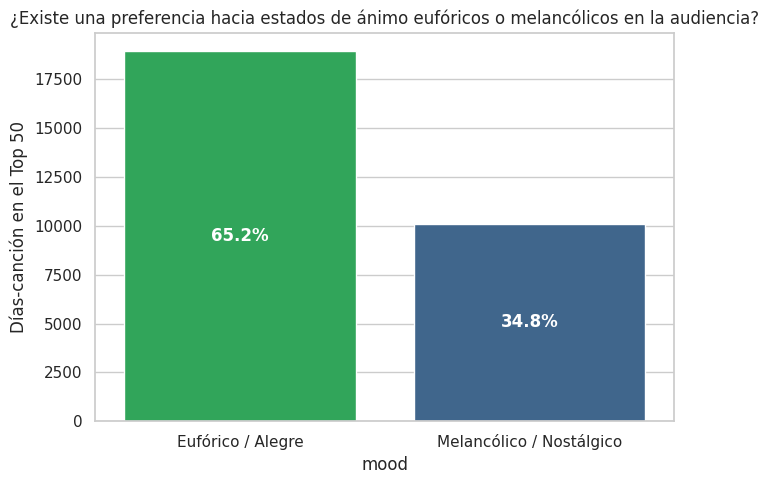

KPI 1 - Porcentaje de Consumo Eufórico: 65.2%
KPI 2 - Valence Promedio General: 0.60


In [16]:

col_valence = col_valence_full

df_chart['mood'] = np.where(df_chart[col_valence] >= 0.5, 'Eufórico / Alegre', 'Melancólico / Nostálgico')
mood_counts = df_chart['mood'].value_counts()

kpi1_euphoric_pct = (mood_counts.get('Eufórico / Alegre', 0) / len(df_chart)) * 100
kpi2_avg_valence_gen = df_chart[col_valence].mean()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=mood_counts.index, y=mood_counts.values, hue=mood_counts.index, legend=False, palette=['#1DB954', '#336699'])
plt.title('¿Existe una preferencia hacia estados de ánimo eufóricos o melancólicos en la audiencia?')
plt.ylabel('Días-canción en el Top 50')

for p in ax.patches:
    ax.annotate(f'{(p.get_height()/len(df_chart))*100:.1f}%', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"KPI 1 - Porcentaje de Consumo Eufórico: {kpi1_euphoric_pct:.1f}%")
print(f"KPI 2 - Valence Promedio General: {kpi2_avg_valence_gen:.2f}")

**HALLAZGO:** El 65.2% del consumo del Top 50 Perú corresponde a canciones de ánimo eufórico o alegre (valence ≥ 0.5), con una positividad promedio de 0.60. El oyente peruano usa el streaming sobre todo para el entretenimiento activo (fiesta, baile, energía), más que para la escucha introspectiva.

El modelo supervisado lo confirma: con todo lo demás igual, las canciones más alegres permanecen 32% más días en el chart. Para Latam Music Group, el catálogo debe orientarse hacia canciones de ánimo positivo.

### 8.¿Qué países de origen concentran el catálogo internacional que domina el consumo del Top 50 peruano?

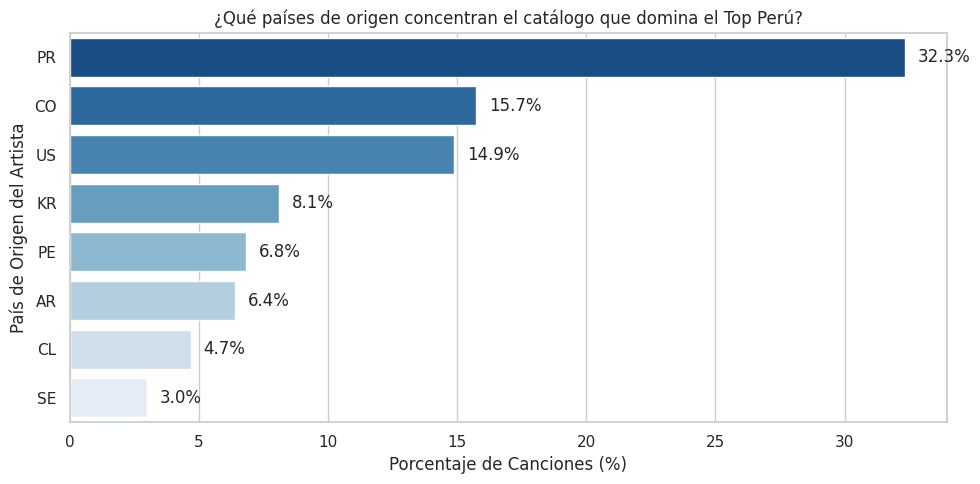

KPI 1 - Cuota del País Líder (PR): 32.3%
KPI 2 - Concentración Top 3 Países: 63.0%
Cuota de artistas peruanos: 6.8% 


In [17]:

df_p8 = df_chart.dropna(subset=['artist_country']).copy()
df_p8 = df_p8[df_p8['artist_country'].astype(str).str.strip() != 'Unknown']
n_total_p8 = df_chart['clean_title'].nunique()
n_valido_p8 = df_p8['clean_title'].nunique()
cobertura_p8 = (n_valido_p8 / n_total_p8) * 100


pct_local = (df_p8.drop_duplicates(subset=['clean_title'])['artist_country']
             .astype(str).str.upper().str.strip().eq('PE').mean() * 100)

country_counts = (
    df_p8.drop_duplicates(subset=['clean_title'])['artist_country']
    .value_counts(normalize=True) * 100
)
top_countries = country_counts.head(8)

kpi1_share_top_country = top_countries.iloc[0]
kpi2_share_top3_countries = top_countries.head(3).sum()

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_countries.values, y=top_countries.index, hue=top_countries.index, legend=False, palette='Blues_r')
plt.title('¿Qué países de origen concentran el catálogo que domina el Top Perú?')
plt.xlabel('Porcentaje de Canciones (%)')
plt.ylabel('País de Origen del Artista')

for p in ax.patches:
    ax.annotate(f'{p.get_width():.1f}%', (p.get_width() + 0.5, p.get_y() + p.get_height() / 2), va='center')

plt.tight_layout()
plt.show()

print(f"KPI 1 - Cuota del País Líder ({top_countries.index[0]}): {kpi1_share_top_country:.1f}%")
print(f"KPI 2 - Concentración Top 3 Países: {kpi2_share_top3_countries:.1f}%")
print(f"Cuota de artistas peruanos: {pct_local:.1f}% ")


**HALLAZGO:** Puerto Rico es el país de origen líder, con el 32.3% de las canciones con país identificado. Le siguen Colombia (15.7%) y Estados Unidos (14.9%), y los tres juntos concentran el 63.0% del catálogo. Detrás aparecen Corea del Sur (8.1%) y recién después Perú, con 6.8%. El mercado peruano consume sobre todo urbano latino importado del Caribe y Colombia.

Para Latam Music Group, esto tiene dos lecturas. La competencia directa son los catálogos de Puerto Rico y Colombia, que definen el sonido dominante. Al mismo tiempo, el talento local tiene poca presencia en el chart, lo que abre un espacio de diferenciación: un artista peruano con el perfil sonoro ganador competiría en un segmento con poca oferta local.

# Fase 2 — Modelo supervisado: ¿qué predice la permanencia en el Top 50 Perú?
         
**Objetivo:** responder la pregunta huérfana: *¿qué combinación de perfil sonoro y perfil de talento predice mejor la permanencia de una canción en el Top 50 peruano, y qué peso relativo tiene cada factor?*

**Modelo:** regresión lineal (mínimos cuadrados ordinarios) con errores estándar robustos (HC3).

- **Unidad de análisis:** una canción.
- **Variable objetivo:** días en el Top 50, transformada a log(1 + días). La permanencia es muy asimétrica (mediana de 23 días, máximo de 532). Con la transformación, cada coeficiente se lee como "% más o menos días en el chart".
- **Predictores, en tres bloques:**
  - **Sonido** (dataset base): bailabilidad, energía, positividad y tempo. Están estandarizadas: el efecto corresponde a subir una desviación estándar.
  - **Lanzamiento** (dataset base): duración, colaboración (*feat.*) y contenido explícito.
  - **Talento** (enriquecimiento MusicBrainz): tipo de artista, país de origen y macro-género. Cada categoría se compara contra la más frecuente.
- **Exclusiones:**
  - Canciones con permanencia censurada: ya estaban en el chart al inicio de la ventana o seguían en él al cierre, así que no se conoce su permanencia real.
  - Canciones sin artista identificado en MusicBrainz.
- **Métricas:**
  - R² y RMSE, las métricas de regresión: qué % de la variación explica el modelo y cuánto se equivoca en promedio.
  - Train/test con validación cruzada de 5 pliegues: se separan los datos en entrenamiento y prueba 5 veces distintas, y se evalúa siempre en canciones que el modelo no vio. Así se detecta el overfitting.
  - Error absoluto medio en días, comparado con un modelo ingenuo que siempre predice lo típico.
- **Peso relativo:** cuántos puntos de R² se pierden al quitar cada bloque. El modelo se compara con y sin las variables de MusicBrainz para medir cuánto aporta el enriquecimiento.

**Por qué se excluye la posición de debut:** el puesto con el que una canción entra al chart se conoce recién después del lanzamiento. El cliente necesita factores que pueda evaluar antes de fichar.

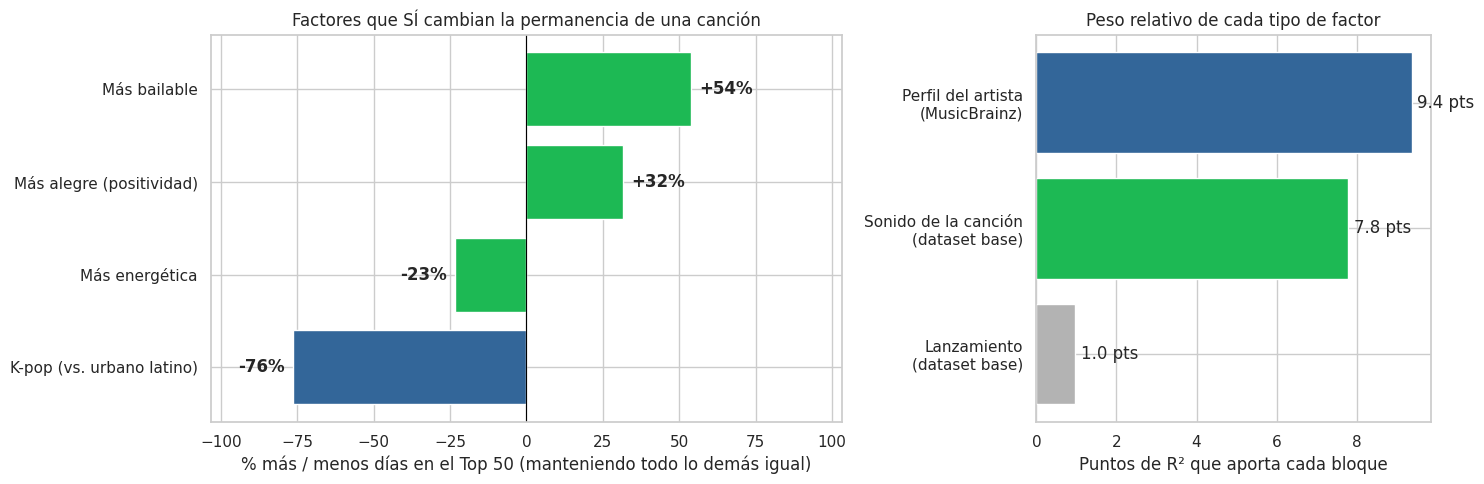

Canciones en el modelo: 199 (se excluyen 98 con permanencia censurada y 87 sin artista identificado en MusicBrainz)
R² = 0.257 (ajustado 0.187) | R² fuera de muestra = 0.108 (sin MusicBrainz: 0.089)
Error absoluto medio = 46.8 días vs. 49.0 de un modelo ingenuo | RMSE = 79.3 días

Factores con efecto significativo (p < 0.05):
  • Más bailable: +53.7% días en el chart (p = 0.006)
  • Más alegre (positividad): +31.6% días en el chart (p = 0.045)
  • Más energética: -23.3% días en el chart (p = 0.038)
  • K-pop (vs. urbano latino): -76.4% días en el chart (p = 0.005)


In [18]:

import statsmodels.api as sm

df_mod = df_canciones.merge(genero_cancion[['clean_title', 'clean_artist', 'macro_genero']],
                            on=['clean_title', 'clean_artist'], how='left')

df_mod['censura_fin'] = df_mod['ultima_fecha'].eq(fecha_fin)
n_inicial = len(df_mod)
df_mod = df_mod[~df_mod['censura_inicio'] & ~df_mod['censura_fin']].copy()
n_sin_censura = len(df_mod)

df_mod = df_mod[df_mod['artist_type'].isin(['Person', 'Group'])].copy()

df_mod['y'] = np.log1p(df_mod['dias_en_chart'])

SONIDO = {'danceability': 'Bailabilidad', 'energy': 'Energía',
          'valence': 'Positividad (valence)', 'tempo': 'Tempo (BPM)'}

df_mod['colaboracion'] = (df_mod['artists_raw'].astype(str).str.split(',').str.len() > 1).astype(float)
df_mod['explicita'] = df_mod['is_explicit'].astype(str).str.lower().isin(['true', '1']).astype(float)
LANZAMIENTO_NUM = {'duracion_min': 'Duración (min)'}
LANZAMIENTO_BIN = {'colaboracion': 'Colaboración (feat.)', 'explicita': 'Contenido explícito'}

df_mod['Tipo de artista'] = df_mod['artist_type'].map({'Person': 'Solista', 'Group': 'Agrupación'})
PAISES = {'PR': 'Puerto Rico', 'CO': 'Colombia', 'US': 'EE.UU.', 'PE': 'Perú'}
df_mod['Origen'] = np.select(
    [df_mod['artist_country'].isna(), df_mod['artist_country'].isin(list(PAISES))],
    ['Sin dato', df_mod['artist_country'].map(PAISES)], default='Otro país')
df_mod['Género'] = np.select(
    [df_mod['macro_genero'].isna(),
     df_mod['macro_genero'].astype(str).str.startswith('Urbano latino'),
     df_mod['macro_genero'].astype(str).str.startswith('Pop / anglo'),
     df_mod['macro_genero'].eq('K-pop')],
    ['Sin dato', 'Urbano latino', 'Pop / anglo', 'K-pop'], default='Otro género')

for col, otro in [('Origen', 'Otro país'), ('Género', 'Otro género')]:
    conteo = df_mod[col].value_counts()
    df_mod.loc[df_mod[col].isin(conteo[conteo < 8].index) & (df_mod[col] != 'Sin dato'), col] = otro

df_mod = df_mod.dropna(subset=list(SONIDO) + list(LANZAMIENTO_NUM)).copy()

NUM = {**SONIDO, **LANZAMIENTO_NUM}
X_num = (df_mod[list(NUM)] - df_mod[list(NUM)].mean()) / df_mod[list(NUM)].std()
X_num.columns = [f"{NUM[c]} (+1 DE)" for c in NUM]
X_bin = df_mod[list(LANZAMIENTO_BIN)].rename(columns=LANZAMIENTO_BIN)

referencias, dummies = {}, []
for col in ['Tipo de artista', 'Origen', 'Género']:
    ref = df_mod[col].value_counts().idxmax()
    referencias[col] = ref
    d = pd.get_dummies(df_mod[col], prefix=col, prefix_sep=': ', dtype=float)
    dummies.append(d.drop(columns=f'{col}: {ref}'))

X = pd.concat([X_num, X_bin] + dummies, axis=1).astype(float)
y = df_mod['y']

BLOQUES = {**{c: 'Sonido (dataset base)' for c in X_num.columns[:len(SONIDO)]},
           **{c: 'Lanzamiento (dataset base)' for c in list(X_num.columns[len(SONIDO):]) + list(X_bin.columns)},
           **{c: 'Talento (MusicBrainz)' for d in dummies for c in d.columns}}

modelo = sm.OLS(y, sm.add_constant(X)).fit(cov_type='HC3')

ic = modelo.conf_int()
tabla = pd.DataFrame({
    'Bloque': pd.Series(BLOQUES),
    'Efecto en días (%)': (np.exp(modelo.params) - 1) * 100,
    'IC 95% inf (%)': (np.exp(ic[0]) - 1) * 100,
    'IC 95% sup (%)': (np.exp(ic[1]) - 1) * 100,
    'p-valor': modelo.pvalues,
}).drop(index='const')
tabla['¿Significativo?'] = np.where(tabla['p-valor'] < 0.05, 'Sí', 'No')
tabla = tabla.sort_values('Efecto en días (%)')

def r2_cv(X_cv, y_cv, k=5, semilla=42):
    """R², RMSE y MAE fuera de muestra (en días) con validación cruzada k-fold."""
    idx = np.random.default_rng(semilla).permutation(len(X_cv))
    pred = pd.Series(index=y_cv.index, dtype=float)
    for test in np.array_split(idx, k):
        train = np.setdiff1d(idx, test)
        m = sm.OLS(y_cv.iloc[train], sm.add_constant(X_cv.iloc[train], has_constant='add')).fit()
        pred.iloc[test] = m.predict(sm.add_constant(X_cv.iloc[test], has_constant='add'))
    r2 = 1 - ((y_cv - pred) ** 2).sum() / ((y_cv - y_cv.mean()) ** 2).sum()
    dias_real, dias_pred = np.expm1(y_cv), np.expm1(pred)
    rmse = np.sqrt(((dias_real - dias_pred) ** 2).mean())
    mae = (dias_real - dias_pred).abs().mean()
    return r2, rmse, mae

r2_full, rmse_full, mae_full = r2_cv(X, y)
mae_base = (np.expm1(y) - np.expm1(y.mean())).abs().mean()

aporte = {}
for bloque in ['Sonido (dataset base)', 'Lanzamiento (dataset base)', 'Talento (MusicBrainz)']:
    cols_sin = [c for c in X.columns if BLOQUES[c] != bloque]
    r2_sin = sm.OLS(y, sm.add_constant(X[cols_sin])).fit().rsquared
    aporte[bloque] = (modelo.rsquared - r2_sin) * 100
aporte = pd.Series(aporte).sort_values()

cols_base = [c for c in X.columns if BLOQUES[c] != 'Talento (MusicBrainz)']
r2_base_cv, _, mae_base_cv = r2_cv(X[cols_base], y)

ETIQUETAS = {'Bailabilidad (+1 DE)': 'Más bailable',
             'Positividad (valence) (+1 DE)': 'Más alegre (positividad)',
             'Energía (+1 DE)': 'Más energética',
             'Tempo (BPM) (+1 DE)': 'Más rápida (tempo)',
             'Duración (min) (+1 DE)': 'Más larga',
             'Género: K-pop': 'K-pop (vs. urbano latino)',
             'Tipo de artista: Agrupación': 'Agrupación (vs. solista)'}
NOMBRES_BLOQUE = {'Sonido (dataset base)': 'Sonido de la canción\n(dataset base)',
                  'Lanzamiento (dataset base)': 'Lanzamiento\n(dataset base)',
                  'Talento (MusicBrainz)': 'Perfil del artista\n(MusicBrainz)'}
COLORES = {'Sonido (dataset base)': '#1DB954', 'Lanzamiento (dataset base)': '#B3B3B3',
           'Talento (MusicBrainz)': '#336699'}

sig = tabla[tabla['¿Significativo?'] == 'Sí'].sort_values('Efecto en días (%)').copy()
sig.index = [ETIQUETAS.get(i, i) for i in sig.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1.6, 1]})

ax = axes[0]
ax.barh(sig.index, sig['Efecto en días (%)'], color=[COLORES[b] for b in sig['Bloque']])
for i, (var, r) in enumerate(sig.iterrows()):
    ax.annotate(f"{r['Efecto en días (%)']:+.0f}%", (r['Efecto en días (%)'], i),
                xytext=(6 if r['Efecto en días (%)'] > 0 else -6, 0), textcoords='offset points',
                ha='left' if r['Efecto en días (%)'] > 0 else 'right', va='center', fontweight='bold')
ax.axvline(0, color='black', lw=0.8)
lim = sig['Efecto en días (%)'].abs().max() * 1.35 if len(sig) else 100
ax.set_xlim(-lim, lim)
ax.set_xlabel('% más / menos días en el Top 50 (manteniendo todo lo demás igual)')
ax.set_title('Factores que SÍ cambian la permanencia de una canción')

ax = axes[1]
ax.barh([NOMBRES_BLOQUE[b] for b in aporte.index], aporte.values, color=[COLORES[b] for b in aporte.index])
for i, v in enumerate(aporte.values):
    ax.annotate(f'{v:.1f} pts', (v, i), xytext=(4, 0), textcoords='offset points', va='center')
ax.set_xlabel('Puntos de R² que aporta cada bloque')
ax.set_title('Peso relativo de cada tipo de factor')
plt.tight_layout()
plt.show()

print(f"Canciones en el modelo: {len(df_mod)} (se excluyen {n_inicial - n_sin_censura} con permanencia censurada "
      f"y {n_sin_censura - len(df_mod)} sin artista identificado en MusicBrainz)")
print(f"R² = {modelo.rsquared:.3f} (ajustado {modelo.rsquared_adj:.3f}) | "
      f"R² fuera de muestra = {r2_full:.3f} (sin MusicBrainz: {r2_base_cv:.3f})")
print(f"Error absoluto medio = {mae_full:.1f} días vs. {mae_base:.1f} de un modelo ingenuo | RMSE = {rmse_full:.1f} días")
print("\nFactores con efecto significativo (p < 0.05):")
for var, r in sig.sort_values('Efecto en días (%)', ascending=False).iterrows():
    print(f"  • {var}: {r['Efecto en días (%)']:+.1f}% días en el chart (p = {r['p-valor']:.3f})")


**HALLAZGO DEL MODELO:**

**Calidad del modelo.**
- Explica el 25.7% de las diferencias de permanencia entre canciones (R² ajustado: 18.7%) y el 10.8% en canciones que no vio al entrenarse (validación cruzada).
- Se equivoca en 46.8 días en promedio, frente a 49.0 días si se predijera siempre lo típico.
- Es un modelo para entender qué factores pesan, no para predecir con exactitud cuánto durará una canción. La permanencia también depende de factores que no están en los datos, como el marketing, los virales o la fama previa del artista. Se analizaron 199 canciones.

**Los 4 factores que sí cambian la permanencia** (manteniendo todo lo demás igual):
- **Bailabilidad: +54% de días en el chart** por cada desviación estándar adicional. Es el factor sonoro más fuerte.
- **Positividad: +32%.** Las canciones más alegres duran más.
- **Energía: −23%.** Con la misma bailabilidad, una canción más intensa dura menos. Lo que dura es bailable, no frenético.
- **K-pop: −76% frente al urbano latino.** Entra al chart pero sale mucho más rápido.

**Lo que NO cambia la permanencia** (no significativo): el país de origen del artista (incluido Perú), si es solista o agrupación, la duración, las colaboraciones, el contenido explícito y el tempo.

**Peso relativo:** el perfil del artista (MusicBrainz) aporta 9.4 puntos de R², el sonido 7.8 y el lanzamiento solo 1.0. **El enriquecimiento cambia la conclusión.** Sin MusicBrainz, el modelo explica el 8.9% fuera de muestra; con MusicBrainz, el 10.8%. El factor más fuerte de todo el modelo (K-pop) solo se ve gracias a los tags de género de MusicBrainz.

# Clustering: perfiles sonoros del Top 50 Perú

**Objetivo:** segmentar las canciones del chart según su sonido, ponerle un nombre de negocio a cada segmento y responder **qué segmento representa la mayor oportunidad** para Latam Music Group.

- **Modelo:** K-means.
- **Unidad de análisis:** una canción.
- **Variables:** bailabilidad, energía, positividad, acústica y rapeado (estandarizadas). El tempo no se usa, porque su medición a "doble tiempo" (EDA 2) crearía grupos artificiales.
- **Número de segmentos:** se usa el método del codo. Como la inercia baja de forma gradual y el codo no es nítido, se complementa con el coeficiente de silueta y se elige el k con mejor silueta entre 3 y 6. K-means usa inicialización **k-means++** con 20 arranques distintos, para evitar la trampa de la inicialización aleatoria.
- **Criterio de oportunidad:** la mediana de días en el chart, entre los segmentos con al menos 10% del consumo.

### **Preparación y número de segmentos:**

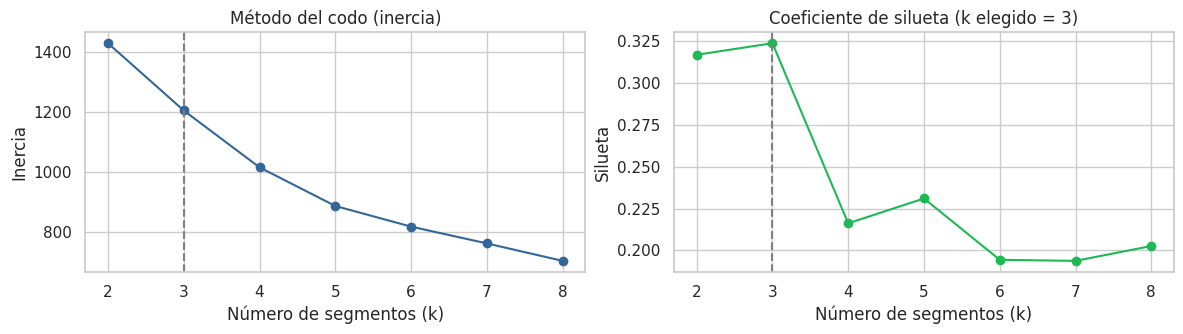

Canciones a segmentar: 384 | k elegido: 3 (silueta = 0.324)


In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

FEATURES = {'danceability': 'Bailabilidad', 'energy': 'Energía', 'valence': 'Positividad',
            'acousticness': 'Acústica', 'speechiness': 'Rapeado'}

df_clu = (df_chart.groupby(['clean_title', 'clean_artist'], as_index=False)
          .agg(**{c: (c, 'mean') for c in FEATURES}, tempo=('tempo', 'mean'),
               dias_chart=('snapshot_date', 'nunique')))
df_clu = df_clu.merge(df_canciones[['clean_title', 'clean_artist', 'censura_inicio', 'ultima_fecha', 'artist_country']],
                      on=['clean_title', 'clean_artist'], how='left')
df_clu = df_clu.merge(genero_cancion[['clean_title', 'clean_artist', 'macro_genero']],
                      on=['clean_title', 'clean_artist'], how='left')
df_clu = df_clu.dropna(subset=list(FEATURES)).reset_index(drop=True)

X_clu = StandardScaler().fit_transform(df_clu[list(FEATURES)])

inercias, siluetas = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_clu)
    inercias[k] = km.inertia_
    siluetas[k] = silhouette_score(X_clu, km.labels_)
K_ELEGIDO = max({k: s for k, s in siluetas.items() if 3 <= k <= 6}.items(), key=lambda kv: kv[1])[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(list(inercias), list(inercias.values()), marker='o', color='#336699')
axes[0].axvline(K_ELEGIDO, ls='--', color='grey')
axes[0].set_title('Método del codo (inercia)')
axes[0].set_xlabel('Número de segmentos (k)')
axes[0].set_ylabel('Inercia')
axes[1].plot(list(siluetas), list(siluetas.values()), marker='o', color='#1DB954')
axes[1].axvline(K_ELEGIDO, ls='--', color='grey')
axes[1].set_title(f'Coeficiente de silueta (k elegido = {K_ELEGIDO})')
axes[1].set_xlabel('Número de segmentos (k)')
axes[1].set_ylabel('Silueta')
plt.tight_layout()
plt.show()
print(f"Canciones a segmentar: {len(df_clu)} | k elegido: {K_ELEGIDO} (silueta = {siluetas[K_ELEGIDO]:.3f})")

### **Modelo final y tabla resumen:**

In [20]:

kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=20, random_state=42).fit(X_clu)
df_clu['cluster'] = kmeans.labels_

z = pd.DataFrame(kmeans.cluster_centers_, columns=list(FEATURES))
RASGOS = {'danceability': ('muy bailable', 'poco bailable'), 'energy': ('intenso', 'suave'),
          'valence': ('alegre', 'melancólico'), 'acousticness': ('acústico', 'electrónico'),
          'speechiness': ('rapeado', 'cantado')}
nombres = {}
for c, p in z.iterrows():
    partes = [RASGOS[f][0] if p[f] > 0 else RASGOS[f][1] for f in p.abs().sort_values(ascending=False).index]
    n = f"{partes[0].capitalize()} y {partes[1]}"
    nombres[c] = n if n not in nombres.values() else f"{n}, {partes[2]}"

NOMBRES_NEGOCIO = {'Electrónico y intenso': 'Fiesta urbana',
                   'Rapeado y melancólico': 'Urbano rapeado (trap)',
                   'Acústico y suave': 'Baladas acústicas'}
df_clu['segmento'] = df_clu['cluster'].map(nombres).replace(NOMBRES_NEGOCIO)

df_clu['censurada'] = df_clu['censura_inicio'].fillna(False) | df_clu['ultima_fecha'].eq(df_chart['snapshot_date'].max())

resumen = df_clu.groupby('segmento').agg(
    Canciones=('clean_title', 'size'),
    dias_cancion=('dias_chart', 'sum'),
    **{FEATURES[c]: (c, 'mean') for c in FEATURES},
    **{'Tempo mediano (BPM)': ('tempo', 'median')})
resumen['% del consumo'] = resumen['dias_cancion'] / resumen['dias_cancion'].sum() * 100
resumen['Mediana días en chart'] = df_clu[~df_clu['censurada']].groupby('segmento')['dias_chart'].median()
resumen['% supera 7 días'] = df_clu[~df_clu['censurada']].groupby('segmento')['dias_chart'].apply(lambda s: (s > 7).mean() * 100)
resumen['% artistas peruanos'] = df_clu.assign(pe=df_clu['artist_country'].eq('PE')).groupby('segmento')['pe'].mean() * 100
resumen['Género dominante'] = df_clu.groupby('segmento')['macro_genero'].agg(
    lambda s: s.value_counts().index[0] if s.notna().any() else 'Sin dato')
resumen['Ejemplos'] = df_clu.groupby('segmento').apply(
    lambda g: ', '.join(g.nlargest(3, 'dias_chart')['clean_title']), include_groups=False)
resumen = resumen.drop(columns='dias_cancion').sort_values('% del consumo', ascending=False)

display(resumen.round(2))

,Canciones,Bailabilidad,Energía,Positividad,Acústica,Rapeado,Tempo mediano (BPM),% del consumo,Mediana días en chart,% supera 7 días,% artistas peruanos,Género dominante,Ejemplos
segmento,,,,,,,,,,,,,
Fiesta urbana,266,0.74,0.73,0.67,0.18,0.07,105.03,73.91,12.0,56.52,5.26,Urbano latino (reggaetón / trap latino),"luna, es un secreto, feliz cumpleanos ferxxo"
Urbano rapeado (trap),41,0.69,0.60,0.49,0.36,0.31,121.45,13.16,32.0,66.67,2.44,Urbano latino (reggaetón / trap latino),"perro negro, qlona, la cancion"
Baladas acústicas,77,0.55,0.50,0.39,0.51,0.06,110.04,12.92,5.5,46.55,1.30,Urbano latino (reggaetón / trap latino),"columbia, die with a smile, mamichula"


### **Perfil sonoro de cada segmento:**

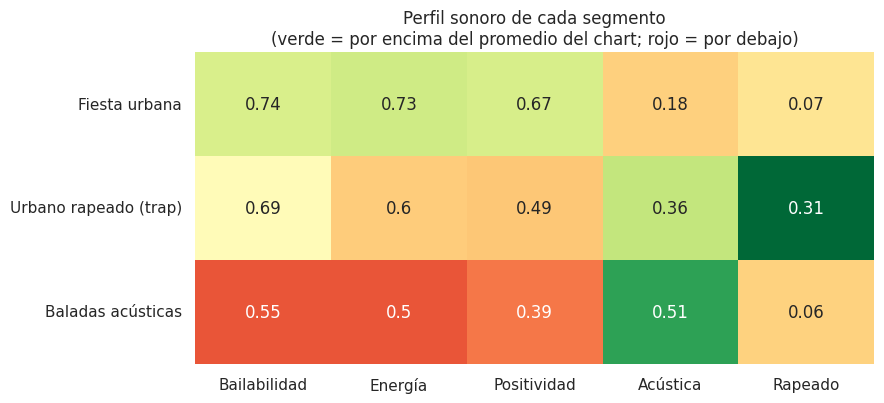

In [21]:

perfil = resumen[list(FEATURES.values())]
perfil_z = (perfil - df_clu[list(FEATURES)].mean().values) / df_clu[list(FEATURES)].std().values

plt.figure(figsize=(9, 0.8 * K_ELEGIDO + 1.8))
sns.heatmap(perfil_z, annot=perfil.round(2), fmt='', cmap='RdYlGn', center=0, vmin=-1.5, vmax=1.5, cbar=False)
plt.title('Perfil sonoro de cada segmento\n(verde = por encima del promedio del chart; rojo = por debajo)')
plt.ylabel('')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### **¿Qué segmento es la mayor oportunidad?**

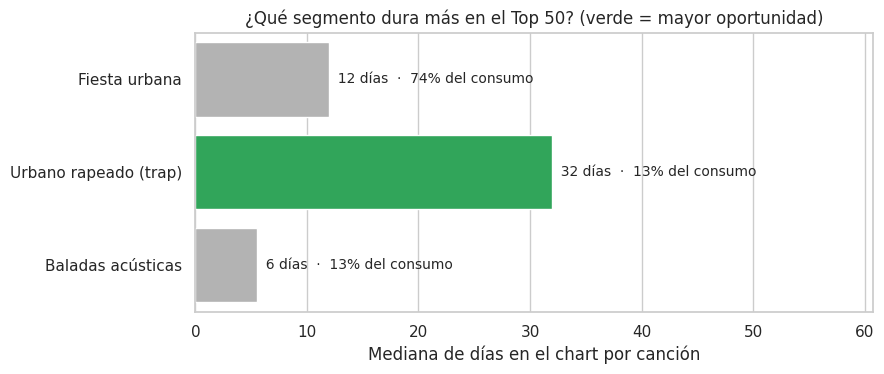

🟢 Segmento de mayor oportunidad: Urbano rapeado (trap)


In [22]:

relevantes = resumen[resumen['% del consumo'] >= 10]
seg_oportunidad = (relevantes if len(relevantes) else resumen)['Mediana días en chart'].idxmax()

plt.figure(figsize=(9, 0.8 * K_ELEGIDO + 1.5))
colores = ['#1DB954' if s == seg_oportunidad else '#B3B3B3' for s in resumen.index]
ax = sns.barplot(x=resumen['Mediana días en chart'], y=resumen.index, hue=resumen.index,
                 palette=colores, legend=False)
for i, (s, r) in enumerate(resumen.iterrows()):
    ax.annotate(f"  {r['Mediana días en chart']:.0f} días  ·  {r['% del consumo']:.0f}% del consumo",
                (r['Mediana días en chart'], i), va='center', fontsize=10)
ax.set_xlim(0, resumen['Mediana días en chart'].max() * 1.9)
plt.title('¿Qué segmento dura más en el Top 50? (verde = mayor oportunidad)')
plt.xlabel('Mediana de días en el chart por canción')
plt.ylabel('')
plt.tight_layout()
plt.show()
print(f"🟢 Segmento de mayor oportunidad: {seg_oportunidad}")

**HALLAZGO DEL CLUSTERING:**

El análisis separa el Top 50 Perú en **3 perfiles sonoros** (silueta = 0.32; es la mejor separación entre 3 y 6 segmentos). Los tres segmentos están dominados por el urbano latino, así que la diferencia entre ellos está en el sonido, no en el género:

| Segmento | Canciones | % del consumo | Mediana días en chart | Supera 7 días | Perfil |
|---|---|---|---|---|---|
| **Fiesta urbana** | 266 | 73.9% | 12 días | 56.5% | El más bailable (0.74), enérgico (0.73) y alegre (0.67) |
| **Urbano rapeado (trap)** | 41 | 13.2% | **32 días** | **66.7%** | Rapeado (0.31), energía media (0.60), positividad media (0.49) |
| **Baladas acústicas** | 77 | 12.9% | 5.5 días | 46.6% | Acústico (0.51), poco bailable (0.55) y melancólico (0.39) |

**Lectura de negocio:**
- **Fiesta urbana es el mercado masivo, pero saturado.** Concentra casi tres cuartos del consumo, pero con 266 canciones compitiendo, cada una dura una mediana de solo 12 días. Lanzar aquí es competir por volumen en un mercado de alta rotación.
- **Urbano rapeado (trap) es la mayor oportunidad.** Cada canción dura casi 3 veces más (32 días) y dos de cada tres superan la primera semana. Con solo 41 canciones, la competencia es mucho menor. Ejemplos: "Perro Negro", "Qlona", "La Canción".
- **Baladas acústicas es el segmento menos rentable.** Sus canciones salen del chart en menos de una semana (mediana de 5.5 días).
- **El talento peruano casi no aparece en ningún segmento** (5.3%, 2.4% y 1.3%). El espacio para artistas locales está libre en los tres.

**Coherencia con el modelo supervisado:** la regresión muestra que, con todo lo demás igual, más positividad suma permanencia (+32%) y más energía la resta (−23%). El trap dura más como estilo gracias a su energía moderada y su estilo rapeado, aunque es menos alegre. Las dos conclusiones se complementan: **conviene apostar por el trap, priorizando dentro de ese estilo las canciones con mayor positividad.**

**Limitación:** el segmento trap tiene solo 41 canciones, y sus ejemplos más duraderos son colaboraciones de artistas consagrados. Parte de su permanencia puede deberse a la fama del artista, que no se mide en los datos. Por eso se recomienda como apuesta complementaria y no como reemplazo del mercado masivo.

# Serie de tiempo: rotación diaria del Top 50 Perú

**Objetivo:** medir cada cuánto se renueva el Top 50 peruano, si hay un patrón semanal y cuántos espacios se abrirán en las próximas semanas. Con eso, Latam Music Group puede planificar cuándo lanzar.

- **Métrica:** canciones que entran al chart cada día, es decir, las que no estaban el día anterior. Como el chart siempre tiene 50 canciones, cada entrada es también una salida.
- **Método:**
  1. Serie diaria con su promedio móvil de 7 días.
  2. Descomposición aditiva (tendencia + patrón semanal + ruido).
  3. Pronóstico de 4 semanas con Holt-Winters (tendencia amortiguada + estacionalidad semanal).
- **Evaluación del pronóstico:** se entrena sin las últimas 4 semanas y se compara contra lo que realmente pasó (error absoluto medio). También se compara con un modelo ingenuo que repite lo del mismo día de la semana anterior.
- **Por qué Holt-Winters:** siguiendo el principio de "empezar simple", se avanzó por los primeros niveles del menú de forecasting: naive (línea base), promedio móvil y Holt-Winters, que capta tendencia y estacionalidad semanal. No se usó ARIMA/SARIMA ni Prophet porque, con menos de dos años de datos, la estacionalidad anual solo aparece dos veces y un modelo más complejo no tendría historia suficiente para aprenderla.

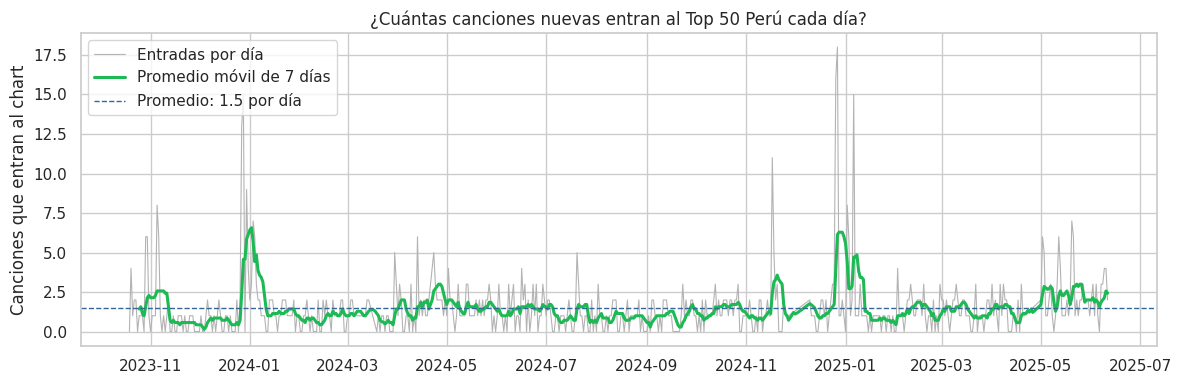

Periodo: 2023-10-19 a 2025-06-11 (602 días; 28 días sin dato completados por interpolación)
Entradas promedio: 1.5 canciones por día ≈ 10 por semana (21% del Top 50 se renueva cada semana)


In [23]:

canciones_dia = (df_chart.groupby('snapshot_date')
                 .apply(lambda g: set(zip(g['clean_title'], g['clean_artist'])), include_groups=False)
                 .sort_index())

registros = []
for i in range(1, len(canciones_dia)):
    hoy, ayer = canciones_dia.index[i], canciones_dia.index[i - 1]
    if (hoy - ayer).days != 1:
        continue
    registros.append({'fecha': hoy, 'entradas': len(canciones_dia.iloc[i] - canciones_dia.iloc[i - 1])})

serie = pd.DataFrame(registros).set_index('fecha')['entradas']
rango = pd.date_range(serie.index.min(), serie.index.max(), freq='D')
n_faltantes = len(rango) - len(serie)
serie = serie.reindex(rango).interpolate()
serie.name = 'entradas'

plt.figure(figsize=(12, 4))
plt.plot(serie.index, serie, color='#B3B3B3', lw=0.8, label='Entradas por día')
plt.plot(serie.index, serie.rolling(7).mean(), color='#1DB954', lw=2.2, label='Promedio móvil de 7 días')
plt.axhline(serie.mean(), color='#336699', ls='--', lw=1, label=f'Promedio: {serie.mean():.1f} por día')
plt.title('¿Cuántas canciones nuevas entran al Top 50 Perú cada día?')
plt.ylabel('Canciones que entran al chart')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"Periodo: {serie.index.min().date()} a {serie.index.max().date()} ({len(serie)} días; "
      f"{n_faltantes} días sin dato completados por interpolación)")
print(f"Entradas promedio: {serie.mean():.1f} canciones por día ≈ {serie.mean() * 7:.0f} por semana "
      f"({serie.mean() * 7 / 50 * 100:.0f}% del Top 50 se renueva cada semana)")

### **Tendencia y patrón semanal:**

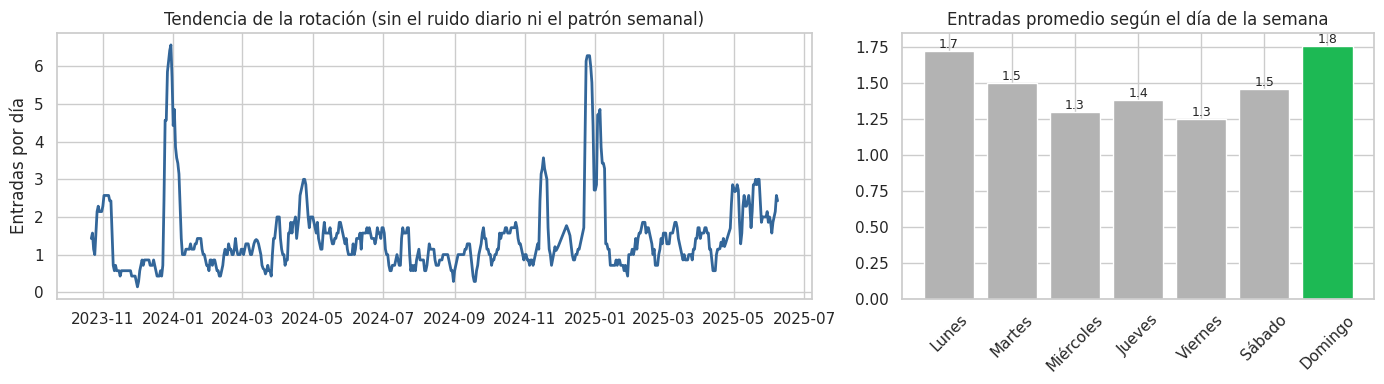

Día con más entradas: Domingo (1.8 en promedio vs. 1.4 el resto de días)
Fuerza del patrón semanal: 0.01 (0 = no hay patrón, 1 = patrón perfecto)
Tendencia: 1.5 entradas/día al inicio vs. 2.3 al final del periodo


In [24]:

from statsmodels.tsa.seasonal import seasonal_decompose

desc = seasonal_decompose(serie, model='additive', period=7)
fuerza_semanal = max(0, 1 - desc.resid.var() / (desc.seasonal + desc.resid).var())

DIAS = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
por_dia = serie.groupby(serie.index.dayofweek).mean()
por_dia.index = DIAS
dia_pico = por_dia.idxmax()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].plot(desc.trend.index, desc.trend, color='#336699', lw=2)
axes[0].set_title('Tendencia de la rotación (sin el ruido diario ni el patrón semanal)')
axes[0].set_ylabel('Entradas por día')

colores = ['#1DB954' if d == dia_pico else '#B3B3B3' for d in DIAS]
axes[1].bar(DIAS, por_dia.values, color=colores)
for i, v in enumerate(por_dia.values):
    axes[1].annotate(f'{v:.1f}', (i, v), ha='center', va='bottom', fontsize=9)
axes[1].set_title('Entradas promedio según el día de la semana')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print(f"Día con más entradas: {dia_pico} ({por_dia.max():.1f} en promedio vs. {por_dia.drop(dia_pico).mean():.1f} el resto de días)")
print(f"Fuerza del patrón semanal: {fuerza_semanal:.2f} (0 = no hay patrón, 1 = patrón perfecto)")
print(f"Tendencia: {desc.trend.dropna().iloc[:30].mean():.1f} entradas/día al inicio vs. "
      f"{desc.trend.dropna().iloc[-30:].mean():.1f} al final del periodo")

### **Pronóstico de las próximas 4 semanas:**

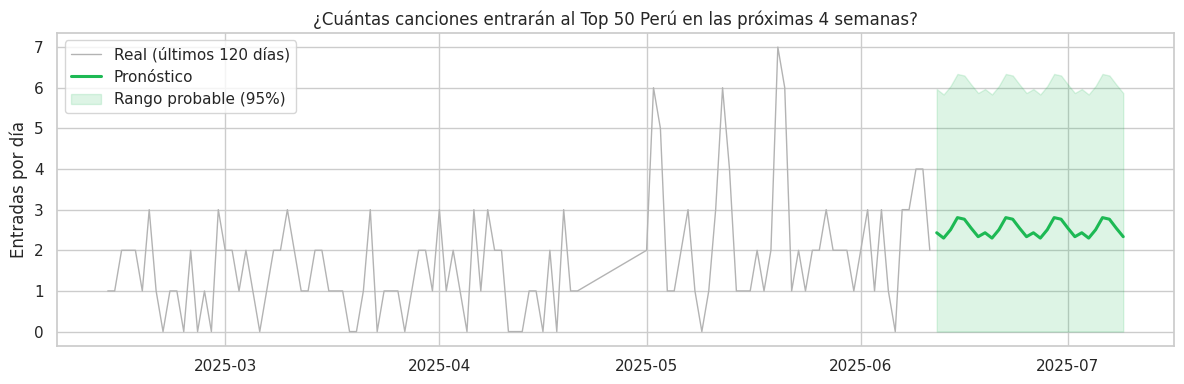

Error del pronóstico (MAE, últimas 4 semanas): 1.17 entradas/día vs. 1.54 del modelo ingenuo → mejor (24% de diferencia)
Error relativo: 51% del promedio de entradas diarias
Pronóstico de entradas por semana:
  • Semana 1: ~18 canciones nuevas en el Top 50
  • Semana 2: ~18 canciones nuevas en el Top 50
  • Semana 3: ~18 canciones nuevas en el Top 50
  • Semana 4: ~18 canciones nuevas en el Top 50


In [25]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing

H = 28

train, test = serie.iloc[:-H], serie.iloc[-H:]
hw_eval = ExponentialSmoothing(train, trend='add', damped_trend=True,
                               seasonal='add', seasonal_periods=7).fit()
pred_test = hw_eval.forecast(H)
naive = serie.shift(7).iloc[-H:]
mae_hw = (test - pred_test).abs().mean()
mae_naive = (test - naive).abs().mean()

hw = ExponentialSmoothing(serie, trend='add', damped_trend=True,
                          seasonal='add', seasonal_periods=7).fit()
futuro = hw.forecast(H).clip(lower=0)
margen = 1.96 * (serie - hw.fittedvalues).std()

hist = serie.iloc[-120:]
plt.figure(figsize=(12, 4))
plt.plot(hist.index, hist, color='#B3B3B3', lw=1, label='Real (últimos 120 días)')
plt.plot(futuro.index, futuro, color='#1DB954', lw=2.2, label='Pronóstico')
plt.fill_between(futuro.index, (futuro - margen).clip(lower=0), futuro + margen,
                 color='#1DB954', alpha=0.15, label='Rango probable (95%)')
plt.title('¿Cuántas canciones entrarán al Top 50 Perú en las próximas 4 semanas?')
plt.ylabel('Entradas por día')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

semanal = futuro.groupby((futuro.index - futuro.index[0]).days // 7).sum()
print(f"Error del pronóstico (MAE, últimas 4 semanas): {mae_hw:.2f} entradas/día "
      f"vs. {mae_naive:.2f} del modelo ingenuo → {'mejor' if mae_hw < mae_naive else 'no mejor'} "
      f"({(1 - mae_hw / mae_naive) * 100:.0f}% de diferencia)")
print(f"Error relativo: {mae_hw / test.mean() * 100:.0f}% del promedio de entradas diarias")
print("Pronóstico de entradas por semana:")
for i, v in semanal.items():
    print(f"  • Semana {i + 1}: ~{v:.0f} canciones nuevas en el Top 50")

**HALLAZGO DE LA SERIE DE TIEMPO:**

**Ritmo normal del chart.** Entre octubre de 2023 y junio de 2025 (602 días), entraron al Top 50 Perú 1.5 canciones nuevas por día en promedio, unas 10 por semana: el 21% del chart se renueva cada semana. Para una disquera, eso significa que cada semana se abren en promedio unos 10 espacios para todos los lanzamientos del mercado.

**El día de la semana casi no importa.** La fuerza del patrón semanal es de 0.01, prácticamente nula. El domingo (1.8 entradas) y el lunes (1.7) superan apenas al viernes (1.3). El día de lanzamiento no es una palanca estratégica real.

**Lo que sí importa es fin de año.** En diciembre y enero de los dos años analizados, la rotación se dispara a un promedio de hasta unas 6.5 entradas por día, más de 4 veces lo normal, con días sueltos de 17 o 18 canciones nuevas. Es el momento del año en que el chart se renueva más y, por lo tanto, en que más espacios se abren.

**La rotación va en aumento.** La tendencia subió de 1.5 a 2.3 entradas por día al final del periodo. El chart peruano se está volviendo más rápido: cada canción tiene menos tiempo para consolidarse.

**Pronóstico.** El modelo Holt-Winters proyecta **unas 18 canciones nuevas por semana durante las próximas 4 semanas** (entre 2 y 3 por día). En las últimas 4 semanas reales, su error fue de 1.17 entradas por día, 24% menor que el de un modelo ingenuo (1.54). El error diario sigue siendo alto (51% del promedio), así que el pronóstico sirve para planificar por semana, no para predecir un día exacto. **Limitación:** con menos de dos años de datos, el modelo no alcanza a aprender el pico anual de diciembre. El pronóstico describe un periodo normal, no la temporada de fin de año.

# Pregunta huérfana

> **¿Qué combinación de perfil sonoro y perfil de talento predice mejor la permanencia de una canción en el Top 50 peruano, y qué peso relativo tiene cada factor?**

**Por qué es irrespondible sin el enriquecimiento:** el chart y el catálogo de Spotify describen la canción (audio features, ranking, fechas), pero no describen al artista. No dicen si es solista o banda, de qué país es ni a qué género pertenece realmente. Esas variables existen solo gracias a MusicBrainz (Vía 2). Sin ellas, el análisis podría hablar del sonido, pero no del talento, que es justo lo que el cliente necesita para decidir a quién fichar.

**Respuesta (modelo supervisado):** la permanencia en el Top 50 peruano la predice mejor la combinación de **un perfil sonoro bailable y alegre, sin exceso de energía** (bailabilidad +54%, positividad +32%, energía −23% de días en el chart) con **un artista de urbano latino** (el K-pop dura 76% menos). Por peso relativo, el perfil del artista es el bloque que más explica (9.4 puntos de R²), seguido del sonido (7.8). Las decisiones de lanzamiento casi no influyen (1.0).

Dos conclusiones solo se ven gracias al enriquecimiento. Primero, el país de origen no cambia la permanencia: no hay evidencia de que un artista peruano con el sonido correcto dure menos que uno puertorriqueño o colombiano. Segundo, que el artista sea solista o agrupación tampoco cambia la permanencia. Los solistas dominan el volumen del chart (P4), pero no duran más.

# Conclusiones

1. **El sonido peruano está claramente definido.** El Top 50 Perú es mucho más bailable que el catálogo mundial (0.74 vs. 0.57) y algo más energético (0.68 vs. 0.64). El pulso dominante es el del reggaetón (95–105 BPM), y el 65.2% del consumo es de ánimo alegre.
2. **El mercado está muy concentrado en un solo género.** El urbano latino captura el 72.0% del consumo, y el Top 3 de macro-géneros (urbano latino, pop/anglo y tropical), el 88.3%. El tropical (7.2%) es el único género con raíz local en el Top 3.
3. **El volumen lo dominan solistas importados.** Los solistas tienen el 86.9% del consumo. Puerto Rico, Colombia y EE.UU. aportan el 63.0% del catálogo identificado; Perú, solo el 6.8%.
4. **El chart es volátil y cada vez más rápido.** La mitad de las canciones dura 23 días o menos, y el 35.9% sale en su primera semana. Cada semana se renueva el 21% del Top 50, y la rotación subió de 1.5 a 2.3 canciones nuevas por día.
5. **Los éxitos que duran son bailables y alegres, pero no frenéticos.** El modelo muestra que la bailabilidad (+54%) y la positividad (+32%) aumentan la permanencia, y que el exceso de energía la reduce (−23%). La duración, las colaboraciones y el contenido explícito no la cambian.
6. **El origen del artista no determina su permanencia, pero el género sí.** Con el sonido y el género correctos, un artista peruano no dura menos que uno importado, y ser solista tampoco garantiza durar más. El K-pop, en cambio, entra al chart pero sale 76% más rápido que el urbano latino.
7. **Dentro del urbano latino hay tres mercados distintos.** Fiesta urbana tiene el volumen (73.9% del consumo), pero está saturada (mediana de 12 días). El trap rinde casi 3 veces más por canción (32 días) con mucha menos competencia. Las baladas acústicas apenas duran una semana.
8. **El momento del año importa más que el día de la semana.** El patrón semanal es prácticamente nulo, pero en diciembre y enero el chart se renueva más de 4 veces más rápido que lo normal.
9. **El enriquecimiento cambió las conclusiones.** El perfil del artista (MusicBrainz) es el bloque que más explica la permanencia (9.4 puntos de R², frente a 7.8 del sonido), y sin él no se habrían detectado ni el efecto del K-pop ni la igualdad de condiciones del talento local.

# Recomendación estratégica

**Para Latam Music Group, la estrategia de entrada a Perú debe combinar dos frentes dentro del urbano latino: competir por volumen en la Fiesta urbana y apostar por el trap como nicho de mayor rendimiento, sumar talento peruano, planificar los lanzamientos según la temporada del año y concentrar la promoción en las primeras semanas.**

1. **Qué fichar (núcleo del portafolio):** artistas de urbano latino (reggaetón / trap latino), el género que concentra el 72% del consumo y frente al cual otros géneros, como el K-pop, duran mucho menos (−76%). Los solistas dominan el volumen del chart (86.9%), pero el modelo no muestra que duren más que las agrupaciones. El criterio de firma debe ser el sonido y el género, no el formato.
2. **Dónde competir (portafolio en dos frentes):**
   - **Volumen: Fiesta urbana** (73.9% del consumo). Es el mercado más grande, pero el más saturado: cada canción dura una mediana de 12 días. Aquí se compite con lanzamientos frecuentes.
   - **Rendimiento: Urbano rapeado (trap).** Cada canción dura una mediana de 32 días (casi 3 veces más) y hay mucha menos competencia (41 canciones). Es la mayor oportunidad por lanzamiento.
   - **Evitar las baladas acústicas:** salen del chart en menos de una semana.
3. **Con qué sonido (filtro de maquetas):** bailabilidad de 0.70 o más y ánimo positivo, que son los dos factores que más alargan la permanencia según el modelo (+54% y +32%). La energía no debe superar el nivel típico del chart (~0.70), porque más intensidad reduce la permanencia (−23%). El pulso típico del chart es de 95 a 105 BPM; sirve como referencia, no como requisito, porque el tempo no cambia la permanencia. **En el trap, priorizar las canciones más alegres dentro del estilo.**
4. **Dónde diferenciarse (talento local):** el modelo no encuentra evidencia de que el origen del artista afecte su permanencia, y el talento peruano tiene muy poca presencia en los tres segmentos (5.3% o menos). Un artista peruano con este perfil sonoro compite en igualdad con el catálogo de Puerto Rico y Colombia, y el espacio está libre. El tropical, tercer género del chart (7.2%), y La Única Tropical, 4.º artista con más días en el chart, muestran que el talento local sí puede sostenerse. **No se recomienda apostar por K-pop**: entra al chart pero sale 76% más rápido.
5. **Cuándo y cómo lanzar:**
   - **Planificar por temporada, no por día de la semana.** El día de lanzamiento casi no cambia nada (patrón semanal de 0.01). En cambio, en diciembre y enero el chart se renueva más de 4 veces más rápido, y es cuando más espacios se abren. Conviene tener lanzamientos fuertes preparados para esa ventana.
   - **Dimensionar la apuesta.** En un periodo normal entran unas 10 canciones nuevas por semana al Top 50 (el pronóstico actual es de unas 18) para todo el mercado. La disquera debe concentrar su inversión en pocos lanzamientos bien elegidos, no en muchos.
   - **Concentrar la promoción en las primeras 1 a 3 semanas:** el 35.9% de los lanzamientos sale del chart en 7 días o menos, y la rotación viene subiendo. Las decisiones de formato (duración, colaboraciones, contenido explícito) casi no influyen en la permanencia, así que no deben ser el foco del presupuesto.
6. **Límites:** el modelo supervisado explica alrededor del 26% de la permanencia; el resto depende de factores que no están en los datos, como el marketing, los virales o la fama previa. El segmento trap tiene solo 41 canciones, y parte de su permanencia puede deberse a artistas consagrados. El pronóstico no capta el pico de fin de año, porque solo hay dos temporadas en los datos. Los datos del perfil de artista cubren alrededor del 70% del consumo. Las conclusiones describen el Top 50 (éxitos), no todo el consumo de streaming en Perú.

# Exportación de datos para el dashboard (Power BI)

Se exportan 7 tablas limpias en `/content/powerbi/`, que se descargan juntas en `powerbi_caso_a.zip`:

| Archivo | Contenido | Uso en el dashboard |
|---|---|---|
| `canciones.csv` | Una fila por canción: nombre, artista, tipo, país, macro-género, segmento, días en el chart y audio features | Tabla principal y filtros |
| `chart_diario.csv` | Una fila por canción y día, con su puesto | Filtros de fecha y evolución del ranking |
| `rotacion_diaria.csv` | Entradas diarias reales y pronóstico de 4 semanas | Serie de tiempo |
| `modelo_factores.csv` | Efecto de cada factor sobre la permanencia | Resultados de la regresión |
| `modelo_bloques.csv` | Peso relativo de cada bloque de factores | Resultados de la regresión |
| `segmentos.csv` | Perfil y valor de negocio de cada segmento | Resultados del clustering |
| `kpis.csv` | Indicadores clave de las 8 preguntas y los modelos | Tarjetas de KPIs |

In [26]:

import shutil

CARPETA = '/content/powerbi'
os.makedirs(CARPETA, exist_ok=True)

PAISES_NOMBRE = {'PR': 'Puerto Rico', 'CO': 'Colombia', 'US': 'EE.UU.', 'KR': 'Corea del Sur', 'PE': 'Perú',
                 'AR': 'Argentina', 'MX': 'México', 'ES': 'España', 'DO': 'Rep. Dominicana', 'VE': 'Venezuela',
                 'CL': 'Chile', 'PA': 'Panamá', 'CA': 'Canadá', 'GB': 'Reino Unido', 'CU': 'Cuba', 'EC': 'Ecuador'}
LLAVE = ['clean_title', 'clean_artist']

nombres_display = df_chart.groupby(LLAVE, as_index=False).agg(cancion=('name', 'first'), artistas=('artists', 'first'))
canciones = (df_canciones
             .merge(nombres_display, on=LLAVE, how='left')
             .merge(genero_cancion[LLAVE + ['macro_genero']], on=LLAVE, how='left')
             .merge(df_clu[LLAVE + ['acousticness', 'speechiness', 'segmento', 'censurada']], on=LLAVE, how='left'))
canciones['id_cancion'] = range(1, len(canciones) + 1)
canciones['tipo_artista'] = canciones['artist_type'].map({'Person': 'Solista', 'Group': 'Agrupación'}).fillna('Sin dato')
canciones['pais_origen'] = canciones['artist_country'].map(PAISES_NOMBRE).fillna(canciones['artist_country']).fillna('Sin dato')
canciones['macro_genero'] = canciones['macro_genero'].fillna('Sin dato')
canciones['segmento'] = canciones['segmento'].fillna('Sin dato')
canciones['supera_7_dias'] = np.where(canciones['dias_en_chart'] > 7, 'Sí', 'No')
canciones['permanencia_conocida'] = np.where(canciones['censurada'].fillna(False), 'No (censurada)', 'Sí')
canciones = canciones[['id_cancion', 'cancion', 'artistas', 'tipo_artista', 'pais_origen', 'macro_genero', 'segmento',
                       'dias_en_chart', 'supera_7_dias', 'permanencia_conocida', 'primera_fecha', 'ultima_fecha',
                       'rank_debut', 'duracion_min', 'danceability', 'energy', 'valence', 'tempo',
                       'acousticness', 'speechiness'] + LLAVE]
canciones = canciones.round({'duracion_min': 2, 'danceability': 3, 'energy': 3, 'valence': 3,
                             'tempo': 1, 'acousticness': 3, 'speechiness': 3})

chart_diario = (df_chart[['snapshot_date', 'daily_rank'] + LLAVE]
                .merge(canciones[['id_cancion'] + LLAVE], on=LLAVE, how='left')
                .drop(columns=LLAVE)
                .rename(columns={'snapshot_date': 'fecha', 'daily_rank': 'puesto'}))
canciones = canciones.drop(columns=LLAVE)

rotacion = pd.DataFrame({'fecha': serie.index, 'entradas': serie.values,
                         'promedio_movil_7d': serie.rolling(7).mean().values, 'tipo': 'Real'})
pronostico = pd.DataFrame({'fecha': futuro.index, 'entradas': futuro.values, 'tipo': 'Pronóstico',
                           'limite_inferior': (futuro - margen).clip(lower=0).values,
                           'limite_superior': (futuro + margen).values})
rotacion = pd.concat([rotacion, pronostico], ignore_index=True)

modelo_factores = (tabla.reset_index().rename(columns={'index': 'factor'})
                   .rename(columns={'Efecto en días (%)': 'efecto_pct', 'IC 95% inf (%)': 'ic_inferior_pct',
                                    'IC 95% sup (%)': 'ic_superior_pct', 'p-valor': 'p_valor',
                                    '¿Significativo?': 'significativo', 'Bloque': 'bloque'}))
modelo_factores['factor'] = modelo_factores['factor'].replace(ETIQUETAS)
modelo_bloques = aporte.rename('puntos_r2').rename_axis('bloque').reset_index()

segmentos = resumen.reset_index()

kpis = pd.DataFrame([
    ('P1', 'Bailabilidad promedio Perú', kpi1_dance_pe, 'índice 0-1'),
    ('P1', 'Bailabilidad promedio global', kpi1_dance_gb, 'índice 0-1'),
    ('P1', 'Energía promedio Perú', kpi2_energy_pe, 'índice 0-1'),
    ('P1', 'Energía promedio global', kpi2_energy_gb, 'índice 0-1'),
    ('P2', 'Cuota del urbano latino', kpi1_share_top, '%'),
    ('P2', 'Concentración Top 3 macro-géneros', kpi2_share_top3, '%'),
    ('P4', 'Cuota de consumo de solistas', kpi1_solo, '%'),
    ('P5', 'Permanencia mediana', days_in_chart.median(), 'días'),
    ('P5', 'Canciones que salen en 7 días o menos', kpi2_turnover_rate, '%'),
    ('P7', 'Consumo de canciones alegres', kpi1_euphoric_pct, '%'),
    ('P8', 'Cuota del país líder (Puerto Rico)', kpi1_share_top_country, '%'),
    ('P8', 'Cuota de artistas peruanos', pct_local, '%'),
    ('Modelo', 'R² del modelo supervisado', modelo.rsquared * 100, '%'),
    ('Serie', 'Canciones nuevas por semana (promedio)', serie.mean() * 7, 'canciones'),
    ('Serie', 'Canciones nuevas por semana (pronóstico)', futuro.mean() * 7, 'canciones'),
], columns=['fuente', 'indicador', 'valor', 'unidad'])
kpis['valor'] = kpis['valor'].round(2)

tablas = {'canciones': canciones, 'chart_diario': chart_diario, 'rotacion_diaria': rotacion,
          'modelo_factores': modelo_factores, 'modelo_bloques': modelo_bloques,
          'segmentos': segmentos, 'kpis': kpis}
for nombre, t in tablas.items():
    t.to_csv(os.path.join(CARPETA, f'{nombre}.csv'), index=False, encoding='utf-8-sig')
    print(f"✅ {nombre}.csv — {len(t):,} filas × {t.shape[1]} columnas")

shutil.make_archive('/content/powerbi_caso_a', 'zip', CARPETA)
print("\n📦 Todo empaquetado en /content/powerbi_caso_a.zip")
try:
    from google.colab import files
    files.download('/content/powerbi_caso_a.zip')
except ImportError:
    pass

✅ canciones.csv — 384 filas × 20 columnas
✅ chart_diario.csv — 29,056 filas × 3 columnas
✅ rotacion_diaria.csv — 630 filas × 6 columnas
✅ modelo_factores.csv — 17 filas × 7 columnas
✅ modelo_bloques.csv — 3 filas × 2 columnas
✅ segmentos.csv — 3 filas × 14 columnas
✅ kpis.csv — 15 filas × 4 columnas

📦 Todo empaquetado en /content/powerbi_caso_a.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>